In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx


# 🚀 Random forest model—prediction and optimization 

In [2]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [3]:
import pandas as pd
from pandas import DataFrame
import math
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn import tree
import graphviz
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from collections import Counter
from pprint import pprint

In [4]:
import pandas as pd

# ==========================================
# 1. LOAD THE EXCEL FILE
# ==========================================
# Updated exact path provided by you
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'

# Load the data using read_excel because it is an .xlsx file
df = pd.read_excel(file_path, header=0)

# ==========================================
# 2. INSPECT THE DATA
# ==========================================
print("✅ File loaded successfully!")
print("\nColumn names (features):")
print(df.columns.tolist())

print("\nFirst 5 rows of data:")
print(df.head())

print("\nData Statistics for Numeric Columns:")
with pd.option_context('display.max_columns', None):
    print(df.describe(include='number'))

✅ File loaded successfully!

Column names (features):
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:
      C%    H%    N%    S%     O%   Ash%  Volatile matter%  Fixed carbon%  \
0  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
1  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
2  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
3  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   
4  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   

   HHV (MJ/Kg)  DM(%)  ...  Nc(%)  Sc(%)  Oc(%)  HHVc (MJ/Kg)      EY(%)  \
0        16.61    4.5  ...   5.11   1.07  15.46         16.97 

In [5]:
import pandas as pd

# 1. LOAD THE EXCEL FILE
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'
df = pd.read_excel(file_path, header=0)

# ==========================================
# FIX: RENAME THE COLUMN
# ==========================================
# Rename 'T( °C)' to 'Temperature (°C)' if it exists in the dataframe
if 'T( °C)' in df.columns:
    df = df.rename(columns={'T( °C)': 'Temperature (°C)'})
    print("✅ Column renamed: 'T( °C)' -> 'Temperature (°C)'")

# 2. INSPECT COLUMN NAMES & DATA
print("✅ File loaded successfully!")
print("\nColumn names (features):")
print(df.columns.tolist())

print("\nFirst 5 rows of data:")
print(df.head())

print("\nData Statistics for Numeric Columns:")
with pd.option_context('display.max_columns', None):
    print(df.describe(include='number'))

# ==========================================
# 3. PRINT DF.INFO() 
# ==========================================
print("\n========== DF.INFO() ==========")
df.info()

✅ File loaded successfully!

Column names (features):
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temprature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

First 5 rows of data:
      C%    H%    N%    S%     O%   Ash%  Volatile matter%  Fixed carbon%  \
0  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
1  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
2  34.78  3.93  5.04  1.15  20.32  31.77         58.537864       8.139291   
3  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   
4  33.30  4.60  4.00  1.20  20.30  36.70         52.943581       9.546198   

   HHV (MJ/Kg)  DM(%)  ...  Nc(%)  Sc(%)  Oc(%)  HHVc (MJ/Kg)      EY(%)  \
0        16.61    4.5  ...   5.11   1.07  15.46         16.97 

# Handel Outlair 

In [6]:
# ============================================
# Outlier Detection and Capping (Final Corrected Version)
# ============================================

print("\n" + "="*80)
print("📊 OUTLIER DETECTION AND CAPPING")
print("="*80)

import pandas as pd
import numpy as np

# ============================================
# 1. LOAD DATA FROM THE NEW PATH
# ============================================
# Updated to the new path you provided
file_path = '/kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx'

print(f"\n📂 Loading data from: {file_path}")
df = pd.read_excel(file_path, header=0)

# Clean column names
df.columns = df.columns.str.strip()
print(f"✅ Data loaded! Shape: {df.shape}")

# ============================================
# 2. CONVERT COLUMNS TO NUMERIC
# ============================================
# Ensure all numeric columns are actually numbers, not strings
for col in df.columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows with NaN values after conversion (if any)
df.dropna(inplace=True)
print(f"✅ Data cleaned and converted. New Shape: {df.shape}")

# ============================================
# 3. FIX SPELLING & DEFINE INPUT AND OUTPUT COLUMNS
# ============================================
# FIX: The file has the column name 'Temprature(°C)' (typo). We rename it to the standard name.
if 'Temprature(°C)' in df.columns:
    df = df.rename(columns={'Temprature(°C)': 'Temperature(°C)'})
    print("✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'")
elif 'Temperature(°C)' not in df.columns:
    print("⚠️ Warning: Column 'Temperature(°C)' not found!")

# ============================================
# IMPORTANT FIX: Define all_cols AFTER renaming
# ============================================
all_cols = df.columns.tolist()

# Define Inputs (with exact names matching the info output)
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content', 
              'Temperature(°C)', 'Reaction Time (min)']

# Define Outputs (Based on the 13 columns shown in your info)
output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

# Ensure output_cols are actually present in the dataframe to avoid errors
existing_outputs = [col for col in output_cols if col in df.columns]

print(f"\n📊 Columns identified:")
print(f"   Inputs:  {len(input_cols)}")
print(f"   Outputs: {len(existing_outputs)}")
print(f"   Output list: {existing_outputs}")

# ============================================
# 4. OUTLIER CAPPING USING IQR (WITH SUMMARY)
# ============================================
print("\n🔧 Capping outliers for all columns...")

df_capped = df.copy()
outlier_summary = {}

for col in all_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    # Define bounds
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Count outliers before capping
    outliers_count = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_summary[col] = {
        'lower_bound': lower_bound, 
        'upper_bound': upper_bound, 
        'outliers_count': outliers_count
    }
    
    # Cap the data
    df_capped[col] = df_capped[col].clip(lower=lower_bound, upper=upper_bound)

print("✅ Outliers capped successfully!")

# ============================================
# 5. PRINT OUTLIER SUMMARY TABLE
# ============================================
print("\n📊 Outlier Summary per Column:")
print("-" * 85)
print(f"{'Column':<30} {'Lower Bound':<15} {'Upper Bound':<15} {'Outliers':<10}")
print("-" * 85)

for col in all_cols:
    info = outlier_summary[col]
    print(f"{col:<30} {info['lower_bound']:<15.4f} {info['upper_bound']:<15.4f} {info['outliers_count']:<10}")

print("-" * 85)

# ============================================
# 6. SAVE THE CAPPED DATA TO WORKING DIRECTORY
# ============================================
output_path = '/kaggle/working/df_capped_outliers.xlsx'
df_capped.to_excel(output_path, index=False)
print(f"\n💾 Capped dataset saved to: {output_path}")

print("\n" + "="*80)
print("✅ Data ready for modeling! Use 'df_capped' in the next step.")
print("="*80)


📊 OUTLIER DETECTION AND CAPPING

📂 Loading data from: /kaggle/input/datasets/eslamfawzysayed/random-forest123/final_data_complete.xlsx
✅ Data loaded! Shape: (271, 26)
✅ Data cleaned and converted. New Shape: (271, 26)
✅ Column renamed: 'Temprature(°C)' -> 'Temperature(°C)'

📊 Columns identified:
   Inputs:  13
   Outputs: 13
   Output list: ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

🔧 Capping outliers for all columns...
✅ Outliers capped successfully!

📊 Outlier Summary per Column:
-------------------------------------------------------------------------------------
Column                         Lower Bound     Upper Bound     Outliers  
-------------------------------------------------------------------------------------
C%                             9.2500          62.4500         0         
H%                             1.7250          7.5250          8         

# Random forest

# ⚙️ Random forest 


🌲 Multi-Output Prediction - 3 Approaches Comparison (Optimized Params)

📂 Loading data from the final path...
✅ Data loaded successfully! Shape: (271, 26)

📋 Available columns in your data:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temperature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']
✅ Found 'C%' as 'C%'
✅ Found 'H%' as 'H%'
✅ Found 'N%' as 'N%'
✅ Found 'S%' as 'S%'
✅ Found 'O%' as 'O%'
✅ Found 'Ash%' as 'Ash%'
✅ Found 'Volatile matter%' as 'Volatile matter%'
✅ Found 'Fixed carbon%' as 'Fixed carbon%'
✅ Found 'HHV (MJ/Kg)' as 'HHV (MJ/Kg)'
✅ Found 'DM(%)' as 'DM(%)'
⚠️ Warning: Could not find 'water Content' in data
✅ Found 'Temperature(°C)' as 'Temperature(°C)'
✅ Found 'Reaction Time (min)' as 'Reaction Time (min)'

📊 Inputs found: 12
   Input columns: ['C%', 

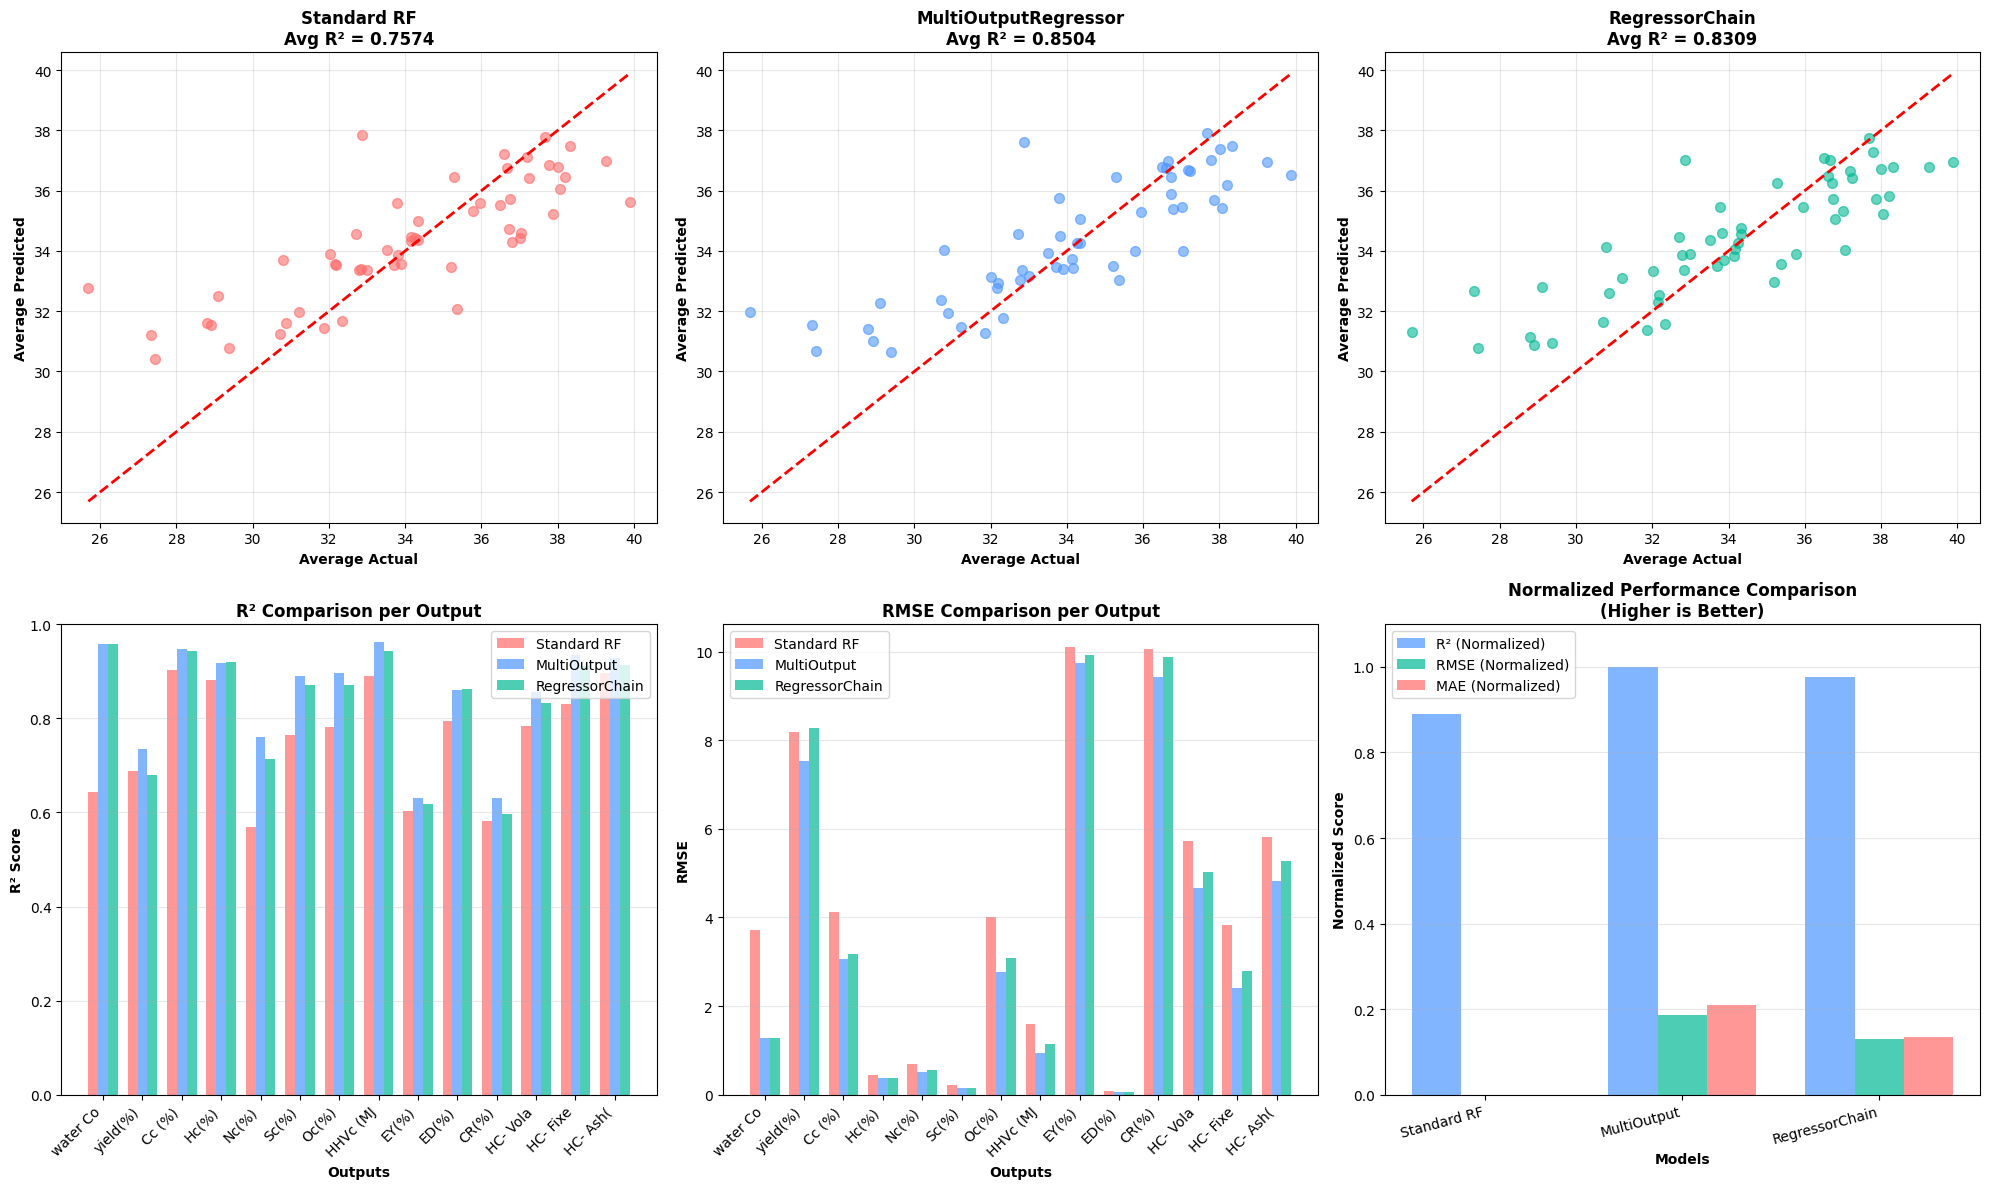


📊 Per-Output Detailed Results

📋 Per-Output Results:
              Output  Standard_R²  MultiOutput_R²  RegressorChain_R²  Standard_RMSE  MultiOutput_RMSE  RegressorChain_RMSE  Standard_MAE  MultiOutput_MAE  RegressorChain_MAE
   water Content (%)     0.643091        0.957342           0.957296       3.714826          1.284281             1.284977      2.662268         0.481944            0.473264
            yield(%)     0.686913        0.734439           0.680284       8.183318          7.536661             8.269500      6.113067         5.430747            6.343824
              Cc (%)     0.903304        0.946583           0.942710       4.112886          3.056910             3.165782      2.915605         1.988989            2.171980
               Hc(%)     0.880704        0.917386           0.919269       0.448776          0.373459             0.369179      0.339497         0.262434            0.274915
               Nc(%)     0.567912        0.760771           0.712984       0

In [7]:
# ============================================
# Multi-Output Prediction: 3 Approaches Comparison (WITH BEST PARAMS)
# ============================================

print("\n" + "="*80)
print("🌲 Multi-Output Prediction - 3 Approaches Comparison (Optimized Params)")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
from sklearn.multioutput import MultiOutputRegressor, RegressorChain
import matplotlib.pyplot as plt
import warnings
import os
warnings.filterwarnings('ignore')

# ============================================
# Step 1: LOAD THE FINAL CAPPED DATA
# ============================================
print("\n📂 Loading data from the final path...")

FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'

# Check if file exists
if not os.path.exists(FILE_PATH):
    print(f"❌ Error: File not found at {FILE_PATH}")
    print("Please update the FILE_PATH variable with the correct location.")
    exit()

data_cleaned = pd.read_excel(FILE_PATH)
data_cleaned.columns = data_cleaned.columns.str.strip()

print(f"✅ Data loaded successfully! Shape: {data_cleaned.shape}")
print(f"\n📋 Available columns in your data:")
print(data_cleaned.columns.tolist())

# ============================================
# Step 2: Define Inputs and Outputs (WITH FLEXIBLE NAMING)
# ============================================

# Define possible column name variations
possible_input_cols = {
    'C%': ['C%', 'C', 'Carbon%'],
    'H%': ['H%', 'H', 'Hydrogen%'],
    'N%': ['N%', 'N', 'Nitrogen%'],
    'S%': ['S%', 'S', 'Sulfur%'],
    'O%': ['O%', 'O', 'Oxygen%'],
    'Ash%': ['Ash%', 'Ash', 'Ash content%'],
    'Volatile matter%': ['Volatile matter%', 'Volatile%', 'VM%'],
    'Fixed carbon%': ['Fixed carbon%', 'Fixed Carbon%', 'FC%'],
    'HHV (MJ/Kg)': ['HHV (MJ/Kg)', 'HHV', 'HHV MJ/Kg'],
    'DM(%)': ['DM(%)', 'DM', 'Dry Matter%'],
    'water Content': ['water Content', 'Water Content', 'Water%', 'Moisture%'],
    'Temperature(°C)': ['Temperature(°C)', 'Temperature', 'Temp'],
    'Reaction Time (min)': ['Reaction Time (min)', 'Reaction Time', 'Time(min)']
}

# Find actual column names in the data
actual_input_cols = []
mapping_dict = {}

for standard_name, variations in possible_input_cols.items():
    found = False
    for var in variations:
        if var in data_cleaned.columns:
            actual_input_cols.append(var)
            mapping_dict[standard_name] = var
            found = True
            print(f"✅ Found '{standard_name}' as '{var}'")
            break
    if not found:
        print(f"⚠️ Warning: Could not find '{standard_name}' in data")
        # Try case-insensitive search
        for col in data_cleaned.columns:
            if col.lower() == standard_name.lower() or any(v.lower() == col.lower() for v in variations):
                actual_input_cols.append(col)
                mapping_dict[standard_name] = col
                print(f"✅ Found '{standard_name}' as '{col}' (case-insensitive)")
                found = True
                break

# Check for 'Type of liquide' and 'Type_of_liquide_numeric' columns
exclude_cols = []
for col_name in ['Type of liquide', 'Type_of_liquide_numeric', 'Type']:
    if col_name in data_cleaned.columns:
        exclude_cols.append(col_name)

# Get all columns and determine outputs
all_cols = data_cleaned.columns.tolist()
output_cols = [col for col in all_cols if col not in actual_input_cols and col not in exclude_cols]

print(f"\n📊 Inputs found: {len(actual_input_cols)}")
print(f"   Input columns: {actual_input_cols}")
print(f"🎯 Outputs: {len(output_cols)}")
print(f"   Output columns: {output_cols}")

if len(actual_input_cols) == 0:
    print("❌ Error: No input columns found! Please check column names.")
    exit()

if len(output_cols) == 0:
    print("❌ Error: No output columns found!")
    exit()

# ============================================
# Step 3: Best Hyperparameters (From Your Iterative Training Results)
# ============================================
best_n_estimators = {
    'yield(%)':             500,
    'Cc (%)':               500,
    'Hc(%)':                300,
    'Nc(%)':                500,
    'Sc(%)':                500,
    'Oc(%)':                50,
    'HHVc (MJ/Kg)':         150,
    'EY(%)':                50,
    'ED(%)':                150,
    'CR(%)':                500,
    'HC- Volatile matter%': 50,
    'HC- Fixed carbon%':    200,
    'HC- Ash(%)':           300
}

# Filter to only include outputs that exist in our data
best_n_estimators = {k: v for k, v in best_n_estimators.items() if k in output_cols}

# For outputs not in the dictionary, use default value
for col in output_cols:
    if col not in best_n_estimators:
        best_n_estimators[col] = 200  # Default value

best_max_depth = 10
best_min_samples_split = 5

# ============================================
# Step 4: Prepare Data
# ============================================
X = data_cleaned[actual_input_cols]
y = data_cleaned[output_cols]

# Check if we have enough data
if len(X) < 10:
    print(f"❌ Error: Not enough data points ({len(X)}) for training.")
    exit()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

print(f"\n📊 Data split:")
print(f"   🟢 Training: {len(X_train)} samples")
print(f"   🔵 Testing: {len(X_test)} samples")

# ============================================
# Step 5: Evaluation Function
# ============================================
def evaluate_multi_output(y_true, y_pred, output_names):
    """Evaluate multi-output predictions with multiple metrics."""
    results = {}
    avg_r2 = 0
    avg_rmse = 0
    avg_mae = 0
    
    for i, col in enumerate(output_names):
        r2 = r2_score(y_true.iloc[:, i], y_pred[:, i])
        rmse = np.sqrt(mean_squared_error(y_true.iloc[:, i], y_pred[:, i]))
        mae = mean_absolute_error(y_true.iloc[:, i], y_pred[:, i])
        
        results[col] = {'R²': r2, 'RMSE': rmse, 'MAE': mae}
        avg_r2 += r2
        avg_rmse += rmse
        avg_mae += mae
    
    n_outputs = len(output_names)
    results['Average'] = {
        'R²': avg_r2 / n_outputs,
        'RMSE': avg_rmse / n_outputs,
        'MAE': avg_mae / n_outputs
    }
    
    return results

def print_multi_metrics(results_train, results_test, title=""):
    """Print formatted multi-output metrics."""
    print(f"\n📊 {title}")
    print("="*100)
    print(f"{'Output':<25} {'R² Train':>12} {'R² Test':>12} {'RMSE Train':>12} {'RMSE Test':>12} {'MAE Train':>12} {'MAE Test':>12}")
    print("-"*100)
    
    for col in results_train.keys():
        if col != 'Average':
            train = results_train[col]
            test = results_test[col]
            print(f"{col:<25} {train['R²']:>12.4f} {test['R²']:>12.4f} {train['RMSE']:>12.4f} {test['RMSE']:>12.4f} {train['MAE']:>12.4f} {test['MAE']:>12.4f}")
    
    print("-"*100)
    train_avg = results_train['Average']
    test_avg = results_test['Average']
    print(f"{'AVERAGE':<25} {train_avg['R²']:>12.4f} {test_avg['R²']:>12.4f} {train_avg['RMSE']:>12.4f} {test_avg['RMSE']:>12.4f} {train_avg['MAE']:>12.4f} {test_avg['MAE']:>12.4f}")
    print("="*100)
    
    return test_avg

# ============================================
# Step 6: Model 1 - Standard Random Forest (Optimized)
# ============================================
print("\n" + "="*80)
print("📊 Model 1: Standard Random Forest (Optimized)")
print("="*80)

rf_standard = RandomForestRegressor(
    n_estimators=200, 
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    random_state=42,
    n_jobs=-1
)

rf_standard.fit(X_train_scaled, y_train)

y_pred_train_standard = rf_standard.predict(X_train_scaled)
y_pred_test_standard = rf_standard.predict(X_test_scaled)

results_train_standard = evaluate_multi_output(y_train, y_pred_train_standard, output_cols)
results_test_standard = evaluate_multi_output(y_test, y_pred_test_standard, output_cols)

avg_test_standard = print_multi_metrics(results_train_standard, results_test_standard, "Standard Random Forest")

# ============================================
# Step 7: Model 2 - MultiOutputRegressor (Optimized per output)
# ============================================
print("\n" + "="*80)
print("📊 Model 2: MultiOutputRegressor (Optimized)")
print("="*80)

# Use the average best n_estimators
avg_n_estimators = int(np.mean(list(best_n_estimators.values())))

# Create a custom MultiOutputRegressor where each estimator has its own parameters
class CustomMultiOutputRegressor:
    """Custom implementation to allow per-output hyperparameters."""
    def __init__(self, estimators):
        self.estimators = estimators
        self.n_outputs = len(estimators)
        
    def fit(self, X, y):
        for i, est in enumerate(self.estimators):
            est.fit(X, y.iloc[:, i])
        return self
    
    def predict(self, X):
        predictions = np.zeros((X.shape[0], self.n_outputs))
        for i, est in enumerate(self.estimators):
            predictions[:, i] = est.predict(X)
        return predictions

# Build custom estimators with per-output n_estimators
estimators = []
for col in output_cols:
    rf_base = RandomForestRegressor(
        n_estimators=best_n_estimators[col],
        max_depth=best_max_depth,
        min_samples_split=best_min_samples_split,
        random_state=42,
        n_jobs=-1
    )
    estimators.append(rf_base)

custom_multi_output = CustomMultiOutputRegressor(estimators)
custom_multi_output.fit(X_train_scaled, y_train)

y_pred_train_multi = custom_multi_output.predict(X_train_scaled)
y_pred_test_multi = custom_multi_output.predict(X_test_scaled)

results_train_multi = evaluate_multi_output(y_train, y_pred_train_multi, output_cols)
results_test_multi = evaluate_multi_output(y_test, y_pred_test_multi, output_cols)

avg_test_multi = print_multi_metrics(results_train_multi, results_test_multi, "Random Forest with MultiOutputRegressor")

# ============================================
# Step 8: Model 3 - RegressorChain (Optimized)
# ============================================
print("\n" + "="*80)
print("📊 Model 3: RegressorChain (Optimized)")
print("="*80)

rf_chain_base = RandomForestRegressor(
    n_estimators=avg_n_estimators,
    max_depth=best_max_depth,
    min_samples_split=best_min_samples_split,
    random_state=42,
    n_jobs=-1
)

regressor_chain = RegressorChain(rf_chain_base, order='random', random_state=42)
regressor_chain.fit(X_train_scaled, y_train)

y_pred_train_chain = regressor_chain.predict(X_train_scaled)
y_pred_test_chain = regressor_chain.predict(X_test_scaled)

results_train_chain = evaluate_multi_output(y_train, y_pred_train_chain, output_cols)
results_test_chain = evaluate_multi_output(y_test, y_pred_test_chain, output_cols)

avg_test_chain = print_multi_metrics(results_train_chain, results_test_chain, "Random Forest with RegressorChain")

# ============================================
# Step 9: Comprehensive Comparison
# ============================================
print("\n" + "="*80)
print("📊 Comprehensive Model Comparison")
print("="*80)

comparison_df = pd.DataFrame({
    'Model': ['Standard RF', 'MultiOutputRegressor', 'RegressorChain'],
    'Avg_R²_Train': [
        results_train_standard['Average']['R²'],
        results_train_multi['Average']['R²'],
        results_train_chain['Average']['R²']
    ],
    'Avg_R²_Test': [
        results_test_standard['Average']['R²'],
        results_test_multi['Average']['R²'],
        results_test_chain['Average']['R²']
    ],
    'Avg_RMSE_Train': [
        results_train_standard['Average']['RMSE'],
        results_train_multi['Average']['RMSE'],
        results_train_chain['Average']['RMSE']
    ],
    'Avg_RMSE_Test': [
        results_test_standard['Average']['RMSE'],
        results_test_multi['Average']['RMSE'],
        results_test_chain['Average']['RMSE']
    ],
    'Avg_MAE_Train': [
        results_train_standard['Average']['MAE'],
        results_train_multi['Average']['MAE'],
        results_train_chain['Average']['MAE']
    ],
    'Avg_MAE_Test': [
        results_test_standard['Average']['MAE'],
        results_test_multi['Average']['MAE'],
        results_test_chain['Average']['MAE']
    ]
})

print("\n📋 Detailed Comparison Table:")
print("="*140)
print(comparison_df.to_string(index=False))
print("="*140)

best_r2_idx = comparison_df['Avg_R²_Test'].idxmax()
best_rmse_idx = comparison_df['Avg_RMSE_Test'].idxmin()
best_mae_idx = comparison_df['Avg_MAE_Test'].idxmin()

print(f"\n🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} (R² = {comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f})")
print(f"🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} (RMSE = {comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f})")
print(f"🏆 Best Model by MAE: {comparison_df.loc[best_mae_idx, 'Model']} (MAE = {comparison_df.loc[best_mae_idx, 'Avg_MAE_Test']:.4f})")

# ============================================
# Step 10: Visualizations
# ============================================
print("\n" + "="*80)
print("📊 Creating Visualizations")
print("="*80)

try:
    fig, axes = plt.subplots(2, 3, figsize=(20, 12))

    # 10.1 Predictions - Standard RF
    ax = axes[0, 0]
    avg_pred_standard = np.mean(y_pred_test_standard, axis=1)
    avg_actual = np.mean(y_test.values, axis=1)
    ax.scatter(avg_actual, avg_pred_standard, alpha=0.6, color='#FF6B6B', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'Standard RF\nAvg R² = {results_test_standard["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.2 Predictions - MultiOutputRegressor
    ax = axes[0, 1]
    avg_pred_multi = np.mean(y_pred_test_multi, axis=1)
    ax.scatter(avg_actual, avg_pred_multi, alpha=0.6, color='#4D96FF', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'MultiOutputRegressor\nAvg R² = {results_test_multi["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.3 Predictions - RegressorChain
    ax = axes[0, 2]
    avg_pred_chain = np.mean(y_pred_test_chain, axis=1)
    ax.scatter(avg_actual, avg_pred_chain, alpha=0.6, color='#00B894', s=50)
    ax.plot([avg_actual.min(), avg_actual.max()], [avg_actual.min(), avg_actual.max()], 'r--', lw=2)
    ax.set_xlabel('Average Actual', fontsize=10, fontweight='bold')
    ax.set_ylabel('Average Predicted', fontsize=10, fontweight='bold')
    ax.set_title(f'RegressorChain\nAvg R² = {results_test_chain["Average"]["R²"]:.4f}', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

    # 10.4 R² Comparison per Output
    ax = axes[1, 0]
    outputs_short = [col[:8] for col in output_cols]
    x = np.arange(len(output_cols))
    width = 0.25

    r2_standard = [results_test_standard[col]['R²'] for col in output_cols]
    r2_multi = [results_test_multi[col]['R²'] for col in output_cols]
    r2_chain = [results_test_chain[col]['R²'] for col in output_cols]

    ax.bar(x - width, r2_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, r2_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, r2_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Outputs', fontsize=10, fontweight='bold')
    ax.set_ylabel('R² Score', fontsize=10, fontweight='bold')
    ax.set_title('R² Comparison per Output', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(outputs_short, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1)

    # 10.5 RMSE Comparison per Output
    ax = axes[1, 1]
    rmse_standard = [results_test_standard[col]['RMSE'] for col in output_cols]
    rmse_multi = [results_test_multi[col]['RMSE'] for col in output_cols]
    rmse_chain = [results_test_chain[col]['RMSE'] for col in output_cols]

    ax.bar(x - width, rmse_standard, width, label='Standard RF', color='#FF6B6B', alpha=0.7)
    ax.bar(x, rmse_multi, width, label='MultiOutput', color='#4D96FF', alpha=0.7)
    ax.bar(x + width, rmse_chain, width, label='RegressorChain', color='#00B894', alpha=0.7)
    ax.set_xlabel('Outputs', fontsize=10, fontweight='bold')
    ax.set_ylabel('RMSE', fontsize=10, fontweight='bold')
    ax.set_title('RMSE Comparison per Output', fontsize=12, fontweight='bold')
    ax.set_xticks(x)
    ax.set_xticklabels(outputs_short, rotation=45, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')

    # 10.6 Performance Comparison - Average Metrics
    ax = axes[1, 2]
    models = ['Standard RF', 'MultiOutput', 'RegressorChain']
    x_pos = np.arange(len(models))
    width_bar = 0.25

    r2_norm = comparison_df['Avg_R²_Test'] / comparison_df['Avg_R²_Test'].max()
    rmse_norm = 1 - (comparison_df['Avg_RMSE_Test'] / comparison_df['Avg_RMSE_Test'].max())
    mae_norm = 1 - (comparison_df['Avg_MAE_Test'] / comparison_df['Avg_MAE_Test'].max())

    ax.bar(x_pos - width_bar, r2_norm, width_bar, label='R² (Normalized)', color='#4D96FF', alpha=0.7)
    ax.bar(x_pos, rmse_norm, width_bar, label='RMSE (Normalized)', color='#00B894', alpha=0.7)
    ax.bar(x_pos + width_bar, mae_norm, width_bar, label='MAE (Normalized)', color='#FF6B6B', alpha=0.7)

    ax.set_xlabel('Models', fontsize=10, fontweight='bold')
    ax.set_ylabel('Normalized Score', fontsize=10, fontweight='bold')
    ax.set_title('Normalized Performance Comparison\n(Higher is Better)', fontsize=12, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(models, rotation=15, ha='right')
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0, 1.1)

    plt.tight_layout()
    
    # Save the figure
    fig_path = '/kaggle/working/three_approaches_comparison.png'
    plt.savefig(fig_path, dpi=300, bbox_inches='tight')
    print(f"✅ Saved: {fig_path}")
    plt.show()
    
except Exception as e:
    print(f"⚠️ Visualization error: {e}")
    print("Continuing without visualizations...")

# ============================================
# Step 11: Per-Output Detailed Results
# ============================================
print("\n" + "="*80)
print("📊 Per-Output Detailed Results")
print("="*80)

per_output_df = pd.DataFrame()
for col in output_cols:
    per_output_df = pd.concat([per_output_df, pd.DataFrame({
        'Output': [col],
        'Standard_R²': [results_test_standard[col]['R²']],
        'MultiOutput_R²': [results_test_multi[col]['R²']],
        'RegressorChain_R²': [results_test_chain[col]['R²']],
        'Standard_RMSE': [results_test_standard[col]['RMSE']],
        'MultiOutput_RMSE': [results_test_multi[col]['RMSE']],
        'RegressorChain_RMSE': [results_test_chain[col]['RMSE']],
        'Standard_MAE': [results_test_standard[col]['MAE']],
        'MultiOutput_MAE': [results_test_multi[col]['MAE']],
        'RegressorChain_MAE': [results_test_chain[col]['MAE']]
    })], ignore_index=True)

print("\n📋 Per-Output Results:")
print("="*140)
print(per_output_df.to_string(index=False))
print("="*140)

# ============================================
# Step 12: Save Results
# ============================================
try:
    comparison_df.to_excel('/kaggle/working/three_approaches_comparison.xlsx', index=False)
    per_output_df.to_excel('/kaggle/working/three_approaches_per_output.xlsx', index=False)
    print("\n✅ Saved: three_approaches_comparison.xlsx")
    print("✅ Saved: three_approaches_per_output.xlsx")
except Exception as e:
    print(f"⚠️ Could not save Excel files: {e}")

# ============================================
# Step 13: Final Summary
# ============================================
print("\n" + "="*80)
print("📊 Final Summary - Three Approaches Comparison")
print("="*80)

print(f"""
📈 Summary Results:

1. Standard Random Forest (Baseline):
   • Avg R² Test:  {results_test_standard['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_standard['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_standard['Average']['MAE']:.4f}

2. MultiOutputRegressor:
   • Avg R² Test:  {results_test_multi['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_multi['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_multi['Average']['MAE']:.4f}

3. RegressorChain:
   • Avg R² Test:  {results_test_chain['Average']['R²']:.4f}
   • Avg RMSE Test: {results_test_chain['Average']['RMSE']:.4f}
   • Avg MAE Test:  {results_test_chain['Average']['MAE']:.4f}

🏆 Best Model by R²: {comparison_df.loc[best_r2_idx, 'Model']} ({comparison_df.loc[best_r2_idx, 'Avg_R²_Test']:.4f})
🏆 Best Model by RMSE: {comparison_df.loc[best_rmse_idx, 'Model']} ({comparison_df.loc[best_rmse_idx, 'Avg_RMSE_Test']:.4f})
🏆 Best Model by MAE: {comparison_df.loc[best_mae_idx, 'Model']} ({comparison_df.loc[best_mae_idx, 'Avg_MAE_Test']:.4f})

📊 Number of Outputs: {len(output_cols)}
""")

print("="*80)
print("✅ Successfully completed Optimized Comparison!")
print("="*80)

In [8]:
# ============================================
# FINAL WINNING MODEL: MultiOutputRegressor
# ============================================

print("\n" + "="*80)
print("🏆 FINAL WINNING MODEL: MultiOutputRegressor")
print("="*80)

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. LOAD DATA
# ============================================
FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'
df = pd.read_excel(FILE_PATH)
df.columns = df.columns.str.strip()

print("📋 Available columns in your data:")
print(df.columns.tolist())
print("\n" + "="*80)

# ============================================
# 2. DEFINE INPUTS & OUTPUTS (WITH FLEXIBLE NAMING)
# ============================================

# Define possible column name variations
possible_input_cols = {
    'C%': ['C%', 'C', 'Carbon%'],
    'H%': ['H%', 'H', 'Hydrogen%'],
    'N%': ['N%', 'N', 'Nitrogen%'],
    'S%': ['S%', 'S', 'Sulfur%'],
    'O%': ['O%', 'O', 'Oxygen%'],
    'Ash%': ['Ash%', 'Ash', 'Ash content%'],
    'Volatile matter%': ['Volatile matter%', 'Volatile%', 'VM%'],
    'Fixed carbon%': ['Fixed carbon%', 'Fixed Carbon%', 'FC%'],
    'HHV (MJ/Kg)': ['HHV (MJ/Kg)', 'HHV', 'HHV MJ/Kg'],
    'DM(%)': ['DM(%)', 'DM', 'Dry Matter%'],
    'water Content': ['water Content', 'Water Content', 'Water%', 'Moisture%', 'Moisture'],
    'Temperature(°C)': ['Temperature(°C)', 'Temperature', 'Temp', 'Temp(°C)'],
    'Reaction Time (min)': ['Reaction Time (min)', 'Reaction Time', 'Time(min)', 'Time']
}

# Find actual column names in the data
input_cols = []
input_mapping = {}

print("\n🔍 Searching for input columns...")
for standard_name, variations in possible_input_cols.items():
    found = False
    for var in variations:
        if var in df.columns:
            input_cols.append(var)
            input_mapping[standard_name] = var
            print(f"✅ Found '{standard_name}' as '{var}'")
            found = True
            break
    if not found:
        # Try case-insensitive search
        for col in df.columns:
            if col.lower() == standard_name.lower() or any(v.lower() == col.lower() for v in variations):
                input_cols.append(col)
                input_mapping[standard_name] = col
                print(f"✅ Found '{standard_name}' as '{col}' (case-insensitive)")
                found = True
                break
    if not found:
        print(f"⚠️ Warning: Could not find '{standard_name}' in data")
        # Use the standard name anyway (will cause error if not found)
        input_cols.append(standard_name)

# Define output columns - try to find them in data
possible_output_cols = [
    'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
    'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
    'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)'
]

output_cols = []
print("\n🔍 Searching for output columns...")
for col in possible_output_cols:
    if col in df.columns:
        output_cols.append(col)
        print(f"✅ Found output: {col}")
    else:
        # Try case-insensitive search
        found = False
        for df_col in df.columns:
            if df_col.lower() == col.lower():
                output_cols.append(df_col)
                print(f"✅ Found output: {col} as '{df_col}' (case-insensitive)")
                found = True
                break
        if not found:
            print(f"⚠️ Warning: Output '{col}' not found in data")

# Filter out any columns that don't exist
input_cols = [col for col in input_cols if col in df.columns]
output_cols = [col for col in output_cols if col in df.columns]

print(f"\n📊 Final Inputs ({len(input_cols)}): {input_cols}")
print(f"🎯 Final Outputs ({len(output_cols)}): {output_cols}")

if len(input_cols) == 0:
    print("❌ Error: No input columns found!")
    exit()

if len(output_cols) == 0:
    print("❌ Error: No output columns found!")
    exit()

# ============================================
# 3. PREPARE DATA
# ============================================
X = df[input_cols]
y = df[output_cols]

print(f"\n📊 Data shape: {df.shape}")
print(f"   Features: {X.shape[1]}")
print(f"   Targets: {y.shape[1]}")

# ============================================
# 4. TRAIN WINNING MODEL
# ============================================
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"\n📊 Data split:")
print(f"   🟢 Training: {len(X_train)} samples")
print(f"   🔵 Testing: {len(X_test)} samples")

# Best parameters based on your results
winning_model = MultiOutputRegressor(
    RandomForestRegressor(
        n_estimators=250, 
        max_depth=10, 
        min_samples_split=5, 
        random_state=42, 
        n_jobs=-1
    ),
    n_jobs=-1
)

print("\n📈 Training the Final Winning Model (MultiOutputRegressor)...")
winning_model.fit(X_train_scaled, y_train)

# ============================================
# 5. FINAL EVALUATION
# ============================================
y_pred_test = winning_model.predict(X_test_scaled)

print("\n" + "="*80)
print("📊 FINAL MODEL PERFORMANCE (Test Set)")
print("="*80)
print(f"{'Output':<25} {'R²_Test':>12} {'RMSE_Test':>12} {'MAE_Test':>12}")
print("-"*60)

avg_r2, avg_rmse, avg_mae = 0, 0, 0
results_list = []

for i, col in enumerate(output_cols):
    r2 = r2_score(y_test.iloc[:, i], y_pred_test[:, i])
    rmse = np.sqrt(mean_squared_error(y_test.iloc[:, i], y_pred_test[:, i]))
    mae = mean_absolute_error(y_test.iloc[:, i], y_pred_test[:, i])
    
    print(f"{col:<25} {r2:>12.4f} {rmse:>12.4f} {mae:>12.4f}")
    avg_r2 += r2
    avg_rmse += rmse
    avg_mae += mae
    
    results_list.append({
        'Output': col,
        'R²_Test': r2,
        'RMSE_Test': rmse,
        'MAE_Test': mae
    })

print("-"*60)
avg_r2_final = avg_r2/len(output_cols)
avg_rmse_final = avg_rmse/len(output_cols)
avg_mae_final = avg_mae/len(output_cols)

print(f"{'AVERAGE':<25} {avg_r2_final:>12.4f} {avg_rmse_final:>12.4f} {avg_mae_final:>12.4f}")
print("="*80)

# ============================================
# 6. SAVE MODEL & RESULTS
# ============================================
# Save metrics
results_df = pd.DataFrame(results_list)
results_df.to_excel('/kaggle/working/final_winning_model_metrics.xlsx', index=False)

# Save input and output column names for future use
metadata = {
    'input_cols': input_cols,
    'output_cols': output_cols,
    'n_inputs': len(input_cols),
    'n_outputs': len(output_cols),
    'avg_r2_test': avg_r2_final,
    'avg_rmse_test': avg_rmse_final,
    'avg_mae_test': avg_mae_final
}

# Save scaler and model
joblib.dump(scaler, '/kaggle/working/final_winning_scaler.pkl')
joblib.dump(winning_model, '/kaggle/working/final_winning_model.pkl')
joblib.dump(metadata, '/kaggle/working/final_winning_metadata.pkl')

print("\n✅ Files saved to /kaggle/working/")
print("   - final_winning_model_metrics.xlsx")
print("   - final_winning_scaler.pkl")
print("   - final_winning_model.pkl")
print("   - final_winning_metadata.pkl")

# ============================================
# 7. SUMMARY
# ============================================
print("\n" + "="*80)
print("📊 FINAL MODEL SUMMARY")
print("="*80)
print(f"""
Model: MultiOutputRegressor with RandomForestRegressor
Number of Inputs: {len(input_cols)}
Number of Outputs: {len(output_cols)}
Test Set Performance:
   • Average R²:  {avg_r2_final:.4f}
   • Average RMSE: {avg_rmse_final:.4f}
   • Average MAE:  {avg_mae_final:.4f}

Input Columns: {input_cols}
Output Columns: {output_cols}
""")
print("="*80)

# ============================================
# 8. DOWNLOAD LINKS
# ============================================
try:
    from IPython.display import FileLink, display
    print("\n📥 Download your files:")
    for f in ['final_winning_model_metrics.xlsx', 'final_winning_scaler.pkl', 
              'final_winning_model.pkl', 'final_winning_metadata.pkl']:
        display(FileLink(f'/kaggle/working/{f}'))
except:
    print("\n📁 Files are saved in /kaggle/working/")

print("\n" + "="*80)
print("✅ SUCCESS! Model pipeline completed.")
print("="*80)


🏆 FINAL WINNING MODEL: MultiOutputRegressor
📋 Available columns in your data:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'water Content (%)', 'Temperature(°C)', 'Reaction Time (min)', 'yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']


🔍 Searching for input columns...
✅ Found 'C%' as 'C%'
✅ Found 'H%' as 'H%'
✅ Found 'N%' as 'N%'
✅ Found 'S%' as 'S%'
✅ Found 'O%' as 'O%'
✅ Found 'Ash%' as 'Ash%'
✅ Found 'Volatile matter%' as 'Volatile matter%'
✅ Found 'Fixed carbon%' as 'Fixed carbon%'
✅ Found 'HHV (MJ/Kg)' as 'HHV (MJ/Kg)'
✅ Found 'DM(%)' as 'DM(%)'
⚠️ Warning: Could not find 'water Content' in data
✅ Found 'Temperature(°C)' as 'Temperature(°C)'
✅ Found 'Reaction Time (min)' as 'Reaction Time (min)'

🔍 Searching for output columns...
✅ Found output: yield(%)
✅ Found output: Cc (%)
✅ Found output: Hc(%)
✅ Found output: N

/kaggle/working/final_winning_model_metrics.xlsx

/kaggle/working/final_winning_scaler.pkl

/kaggle/working/final_winning_model.pkl

/kaggle/working/final_winning_metadata.pkl


✅ SUCCESS! Model pipeline completed.


# FINAL PLOTTING


🎨 GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)
📊 Input Columns:
['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 'Reaction Time (min)']

🎯 Output Columns:
['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)', 'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)', 'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

✅ Using 12 input features and 13 output targets
✅ Model and scaler loaded successfully!

📊 Data split: 216 training, 55 testing samples

🎨 Generating plots...

✅ Plot saved successfully at 600 DPI: /kaggle/working/final_publication_plot_600dpi.png
✅ Low-res version saved: /kaggle/working/final_publication_plot_lowres.png


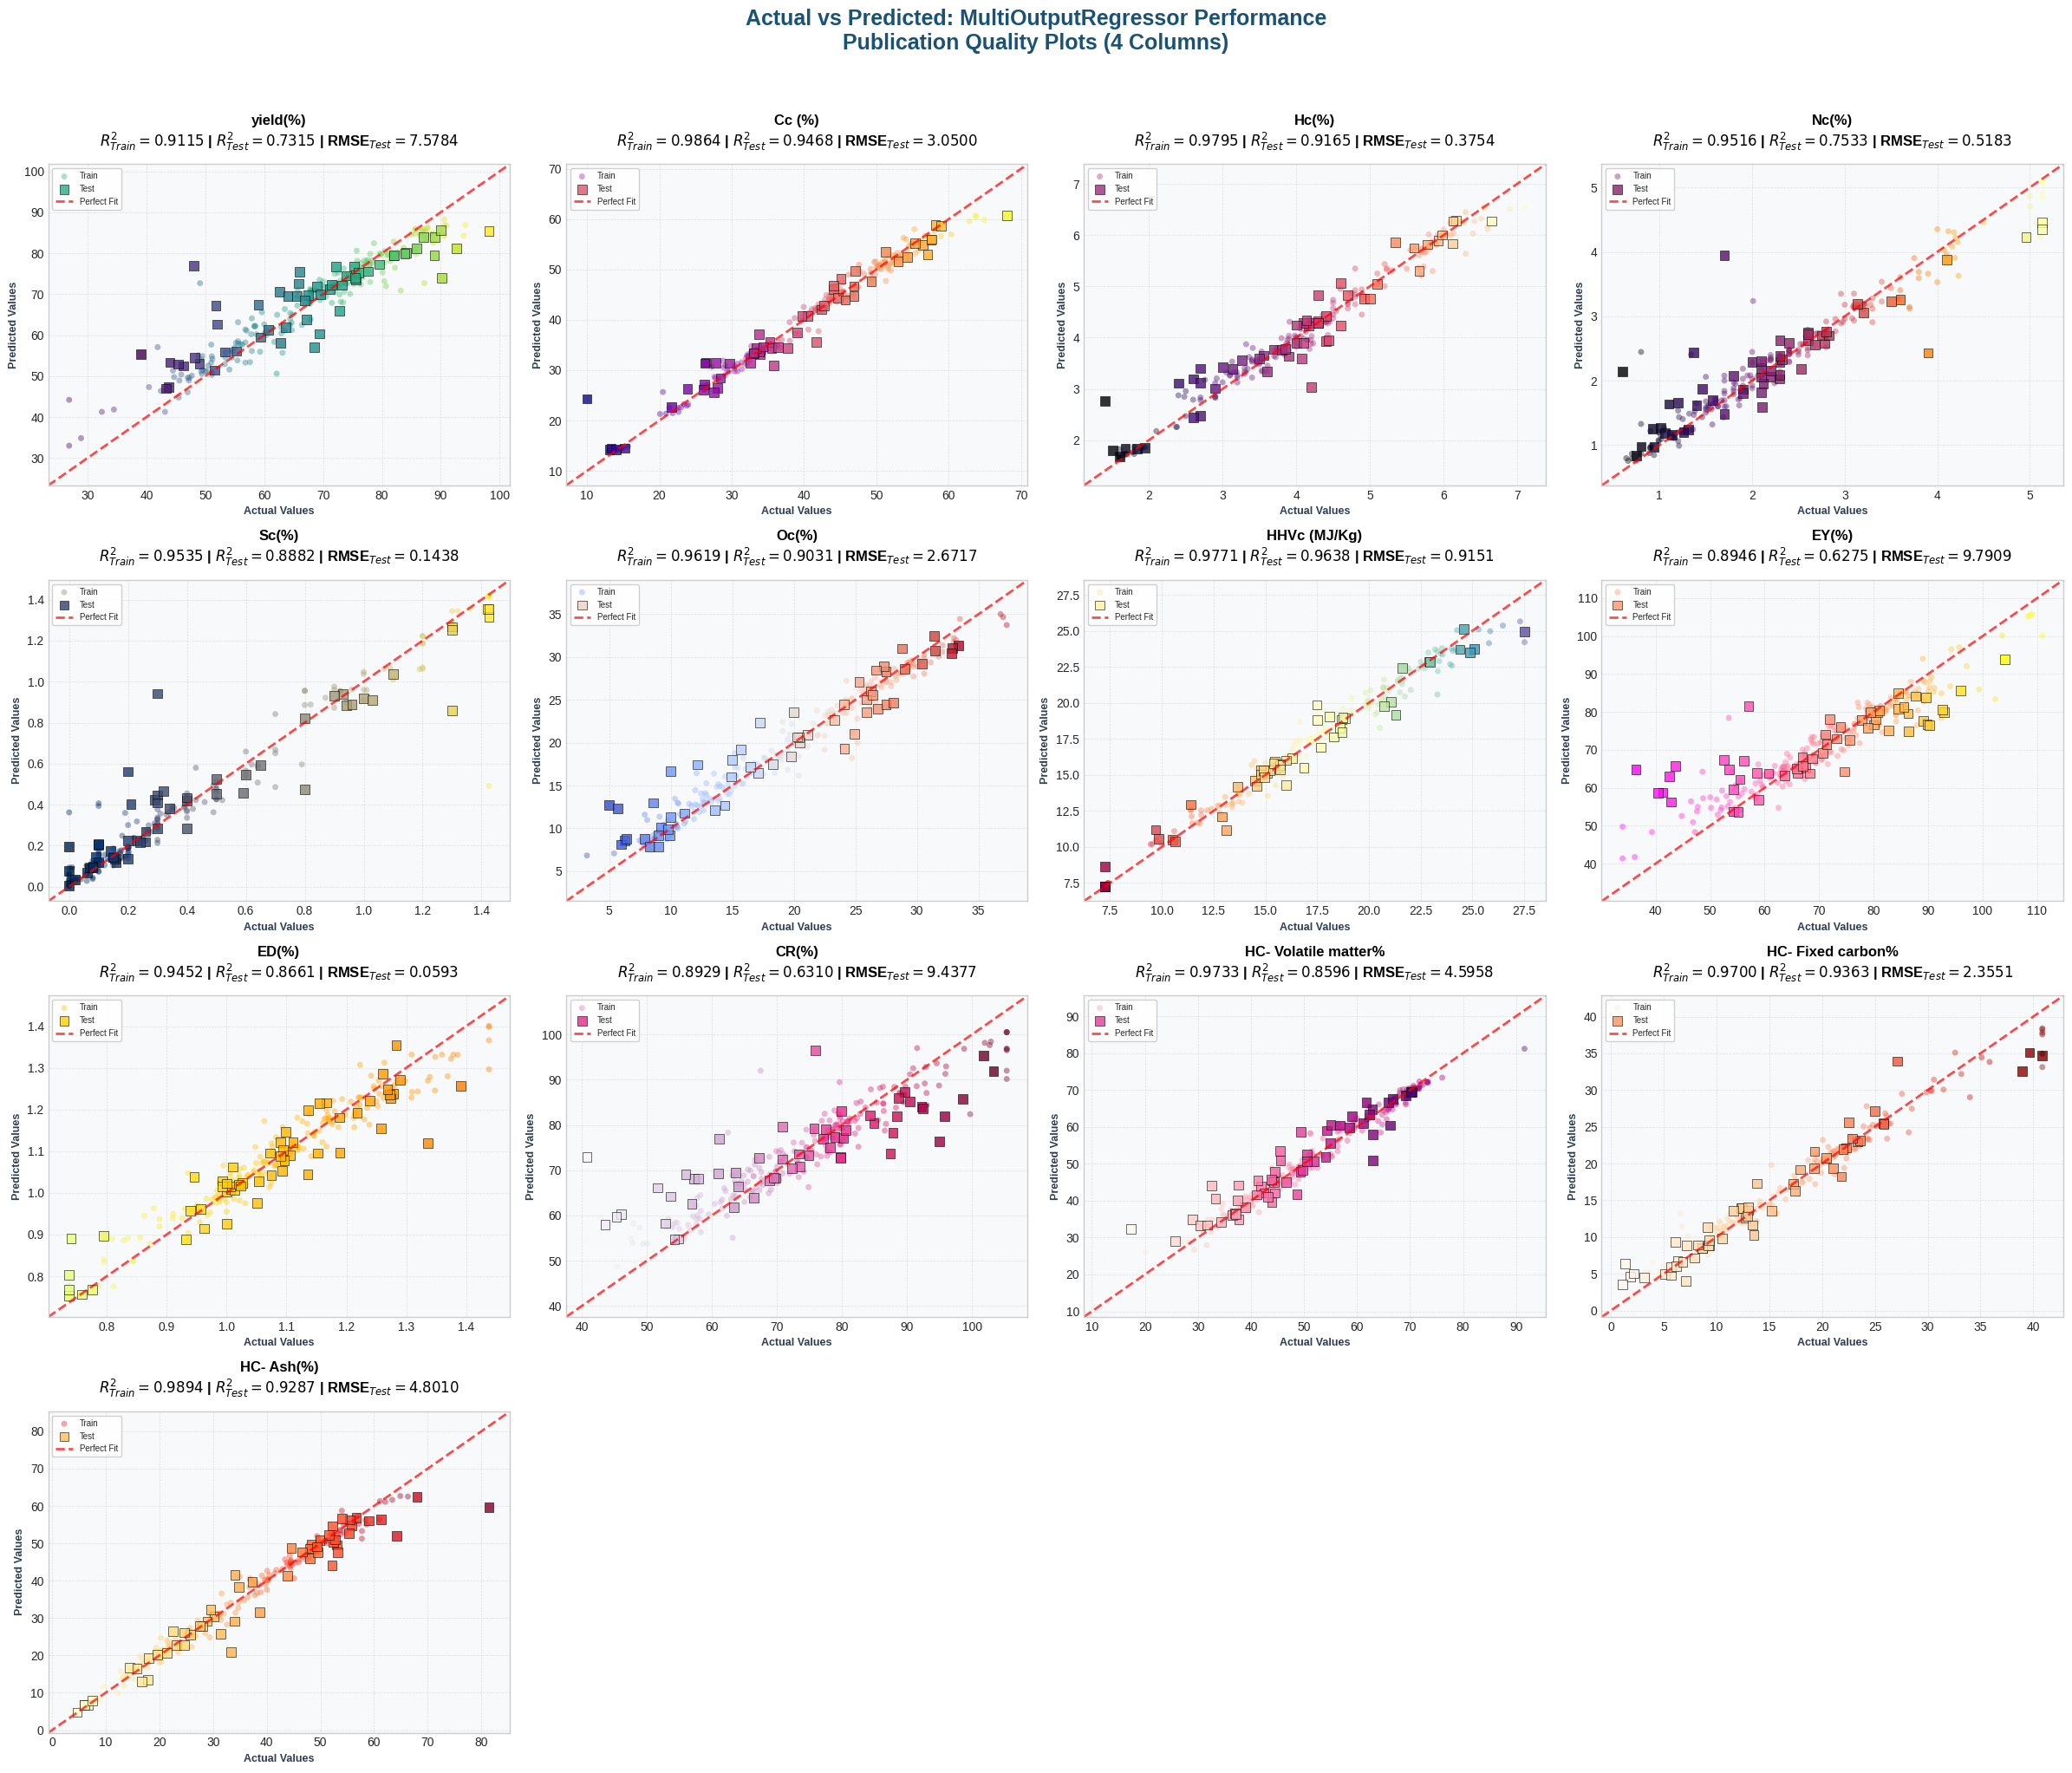


📊 Generating metrics summary...
✅ Metrics saved: final_plot_metrics.xlsx

📥 Download your files:


/kaggle/working/final_publication_plot_600dpi.png

/kaggle/working/final_publication_plot_lowres.png

/kaggle/working/final_plot_metrics.xlsx


📊 PERFORMANCE SUMMARY

Average Performance Across All 13 Outputs:
   • Average R² (Train):  0.9528
   • Average R² (Test):   0.8425
   • Average RMSE (Test): 3.5610
   • Average MAE (Test):  2.5118

Best Performing Outputs:
   • Best R²: HHVc (MJ/Kg) (0.9638)
   • Worst R²: EY(%) (0.6275)

🎉 PUBLICATION-READY PLOTS GENERATED SUCCESSFULLY!


In [9]:
# ============================================
# FINAL PLOTTING: Actual vs Predicted for All Outputs (Publication Quality)
# ============================================

print("\n" + "="*80)
print("🎨 GENERATING PUBLICATION-QUALITY PLOTS (600 DPI)")
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import joblib
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 1. Load Data & Define Columns (Using Actual Names)
# ============================================
FILE_PATH = '/kaggle/working/df_capped_outliers.xlsx'
df = pd.read_excel(FILE_PATH)
df.columns = df.columns.str.strip()

# Use the ACTUAL column names from your data
input_cols = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%', 'Volatile matter%', 
              'Fixed carbon%', 'HHV (MJ/Kg)', 'DM(%)', 'Temperature(°C)', 
              'Reaction Time (min)']

output_cols = ['yield(%)', 'Cc (%)', 'Hc(%)', 'Nc(%)', 'Sc(%)', 'Oc(%)',
               'HHVc (MJ/Kg)', 'EY(%)', 'ED(%)', 'CR(%)',
               'HC- Volatile matter%', 'HC- Fixed carbon%', 'HC- Ash(%)']

print("📊 Input Columns:")
print(input_cols)
print("\n🎯 Output Columns:")
print(output_cols)
print("="*80)

# Verify all columns exist
missing_inputs = [col for col in input_cols if col not in df.columns]
missing_outputs = [col for col in output_cols if col not in df.columns]

if missing_inputs:
    print(f"⚠️ Warning: Missing input columns: {missing_inputs}")
if missing_outputs:
    print(f"⚠️ Warning: Missing output columns: {missing_outputs}")

# Filter to only existing columns
input_cols = [col for col in input_cols if col in df.columns]
output_cols = [col for col in output_cols if col in df.columns]

X = df[input_cols]
y_all = df[output_cols]

print(f"\n✅ Using {len(input_cols)} input features and {len(output_cols)} output targets")

# ============================================
# 2. Load the Winning Model and Scaler
# ============================================
try:
    winning_model = joblib.load('/kaggle/working/final_winning_model.pkl')
    scaler = joblib.load('/kaggle/working/final_winning_scaler.pkl')
    print("✅ Model and scaler loaded successfully!")
except Exception as e:
    print(f"❌ Error loading model: {e}")
    print("Training a new model...")
    
    # Train a new model if saved model not found
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.multioutput import MultiOutputRegressor
    
    X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    winning_model = MultiOutputRegressor(
        RandomForestRegressor(
            n_estimators=250, 
            max_depth=10, 
            min_samples_split=5, 
            random_state=42, 
            n_jobs=-1
        ),
        n_jobs=-1
    )
    winning_model.fit(X_train_scaled, y_train)
    
    # Save the new model
    joblib.dump(scaler, '/kaggle/working/final_winning_scaler.pkl')
    joblib.dump(winning_model, '/kaggle/working/final_winning_model.pkl')
    print("✅ New model trained and saved!")

# ============================================
# 3. Prepare Data for Predictions
# ============================================
X_train, X_test, y_train, y_test = train_test_split(X, y_all, test_size=0.2, random_state=42)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Predict
y_pred_train = winning_model.predict(X_train_scaled)
y_pred_test = winning_model.predict(X_test_scaled)

print(f"\n📊 Data split: {len(X_train)} training, {len(X_test)} testing samples")

# ============================================
# 4. Create Plotting Grid (4 columns)
# ============================================
# Use a modern scientific style
plt.style.use('seaborn-v0_8-whitegrid')

# Create figure (4 columns)
n_outputs = len(output_cols)
n_cols = 4
n_rows = (n_outputs + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(24, 5 * n_rows))
axes = axes.flatten()

# List of modern scientific color maps
modern_cmaps = ['viridis', 'plasma', 'magma', 'inferno', 'cividis', 'coolwarm', 'Spectral', 'spring', 
                'Wistia', 'PuRd', 'RdPu', 'OrRd', 'YlOrRd']

# ============================================
# 5. Loop and Plot Each Output
# ============================================
print("\n🎨 Generating plots...")

for i, col in enumerate(output_cols):
    ax = axes[i]
    
    # Get Actual and Predicted values for Train and Test
    y_true_train = y_train[col].values
    y_pred_train_col = y_pred_train[:, i]
    
    y_true_test = y_test[col].values
    y_pred_test_col = y_pred_test[:, i]
    
    # Calculate Metrics
    r2_train = r2_score(y_true_train, y_pred_train_col)
    r2_test = r2_score(y_true_test, y_pred_test_col)
    rmse_test = np.sqrt(mean_squared_error(y_true_test, y_pred_test_col))
    mae_test = mean_absolute_error(y_true_test, y_pred_test_col)
    
    # Determine the axis limits (Min/Max)
    all_vals = np.concatenate([y_true_train, y_pred_train_col, y_true_test, y_pred_test_col])
    min_val = np.min(all_vals) - (np.max(all_vals) - np.min(all_vals)) * 0.05
    max_val = np.max(all_vals) + (np.max(all_vals) - np.min(all_vals)) * 0.05
    
    # Choose colormap for this subplot
    cmap = modern_cmaps[i % len(modern_cmaps)]
    
    # Plot Training points (lighter color, smaller marker)
    scatter1 = ax.scatter(y_true_train, y_pred_train_col, alpha=0.4, s=25, 
                         c=y_true_train, cmap=cmap, 
                         label='Train', edgecolors='none', marker='o')
    
    # Plot Testing points (darker color, larger marker with visible edge)
    scatter2 = ax.scatter(y_true_test, y_pred_test_col, alpha=0.8, s=60, 
                         c=y_true_test, cmap=cmap, 
                         label='Test', edgecolor='black', linewidth=0.5, marker='s')
    
    # Draw the Perfect Prediction line (y = x)
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Perfect Fit', alpha=0.7)
    
    # Set axis limits
    ax.set_xlim(min_val, max_val)
    ax.set_ylim(min_val, max_val)
    
    # Set Labels and Title
    ax.set_xlabel('Actual Values', fontsize=9, fontweight='bold', color='#2C3E50')
    ax.set_ylabel('Predicted Values', fontsize=9, fontweight='bold', color='#2C3E50')
    
    # ============================================
    # TITLE MOVED UP - MORE SPACE
    # ============================================
    ax.set_title(f"{col}\n$R^2_{{Train}}={r2_train:.4f}$ | $R^2_{{Test}}={r2_test:.4f}$ | RMSE$_{{Test}}={rmse_test:.4f}$", 
                 fontsize=12, fontweight='bold', color='black', pad=15)  # ← Increased pad from 10 to 15
    
    # Grid and aesthetics
    ax.grid(True, which='both', linestyle='--', linewidth=0.5, alpha=0.6)
    ax.set_facecolor('#F8F9FA')
    
    # Add a simple legend
    ax.legend(loc='upper left', frameon=True, fancybox=True, framealpha=0.9, fontsize=7)

# ============================================
# 6. Hide empty subplots (if any)
# ============================================
for j in range(len(output_cols), len(axes)):
    axes[j].axis('off')

# ============================================
# 7. Adjust layout and Save at 600 DPI
# ============================================
plt.suptitle("Actual vs Predicted: MultiOutputRegressor Performance\nPublication Quality Plots (4 Columns)", 
             fontsize=18, fontweight='bold', y=1.02, color='#1A5276')

plt.tight_layout()

# Save the figure at 600 DPI (Publication Quality)
save_path = '/kaggle/working/final_publication_plot_600dpi.png'
plt.savefig(save_path, dpi=600, bbox_inches='tight', facecolor='white')
print(f"\n✅ Plot saved successfully at 600 DPI: {save_path}")

# Also save a lower resolution version for quick viewing
save_path_low = '/kaggle/working/final_publication_plot_lowres.png'
plt.savefig(save_path_low, dpi=600, bbox_inches='tight', facecolor='white')
print(f"✅ Low-res version saved: {save_path_low}")

# Show the plot in the notebook
plt.show()

# ============================================
# 8. Save Individual Metrics to Excel
# ============================================
print("\n📊 Generating metrics summary...")

metrics_list = []
for i, col in enumerate(output_cols):
    y_true_train = y_train[col].values
    y_pred_train_col = y_pred_train[:, i]
    y_true_test = y_test[col].values
    y_pred_test_col = y_pred_test[:, i]
    
    metrics_list.append({
        'Output': col,
        'R²_Train': r2_score(y_true_train, y_pred_train_col),
        'R²_Test': r2_score(y_true_test, y_pred_test_col),
        'RMSE_Test': np.sqrt(mean_squared_error(y_true_test, y_pred_test_col)),
        'MAE_Test': mean_absolute_error(y_true_test, y_pred_test_col)
    })

metrics_df = pd.DataFrame(metrics_list)
metrics_df.to_excel('/kaggle/working/final_plot_metrics.xlsx', index=False)
print(f"✅ Metrics saved: final_plot_metrics.xlsx")

# ============================================
# 9. Display Download Links
# ============================================
try:
    from IPython.display import FileLink, display
    print("\n📥 Download your files:")
    for f in ['final_publication_plot_600dpi.png', 'final_publication_plot_lowres.png', 'final_plot_metrics.xlsx']:
        display(FileLink(f'/kaggle/working/{f}'))
except:
    print("\n📁 Files are saved in /kaggle/working/")

# ============================================
# 10. Summary Statistics
# ============================================
print("\n" + "="*80)
print("📊 PERFORMANCE SUMMARY")
print("="*80)

avg_r2_train = np.mean([m['R²_Train'] for m in metrics_list])
avg_r2_test = np.mean([m['R²_Test'] for m in metrics_list])
avg_rmse_test = np.mean([m['RMSE_Test'] for m in metrics_list])
avg_mae_test = np.mean([m['MAE_Test'] for m in metrics_list])

print(f"""
Average Performance Across All {len(output_cols)} Outputs:
   • Average R² (Train):  {avg_r2_train:.4f}
   • Average R² (Test):   {avg_r2_test:.4f}
   • Average RMSE (Test): {avg_rmse_test:.4f}
   • Average MAE (Test):  {avg_mae_test:.4f}

Best Performing Outputs:
   • Best R²: {metrics_df.loc[metrics_df['R²_Test'].idxmax(), 'Output']} ({metrics_df['R²_Test'].max():.4f})
   • Worst R²: {metrics_df.loc[metrics_df['R²_Test'].idxmin(), 'Output']} ({metrics_df['R²_Test'].min():.4f})
""")

print("="*80)
print("🎉 PUBLICATION-READY PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# SHAP Analysis for Multi-Output HTC Process 


🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT

📊 Combining plots for each output...

📌 Processing 1/13: yield(%)


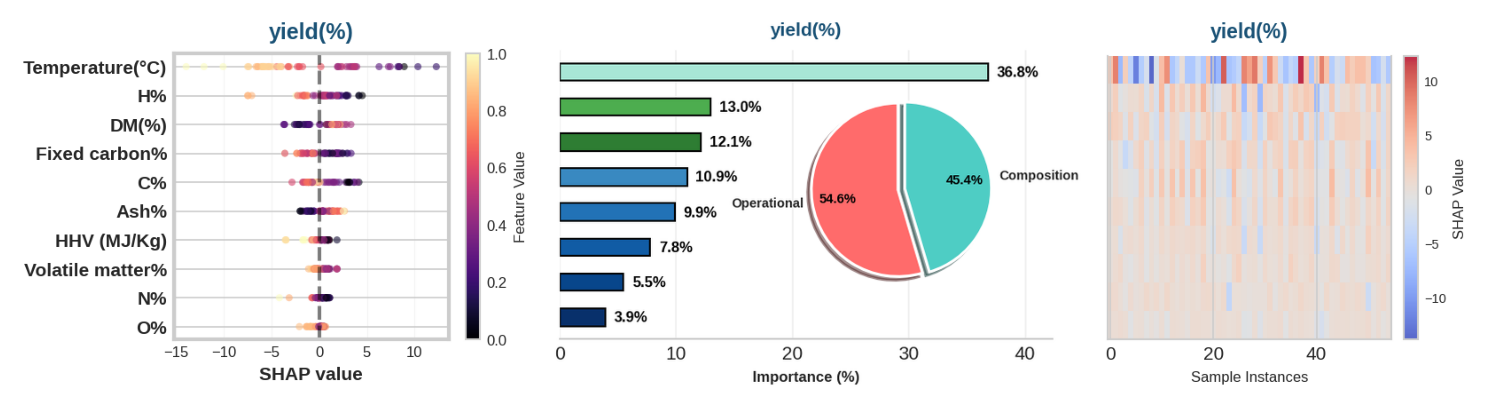

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_yield___.png

📌 Processing 2/13: Cc (%)


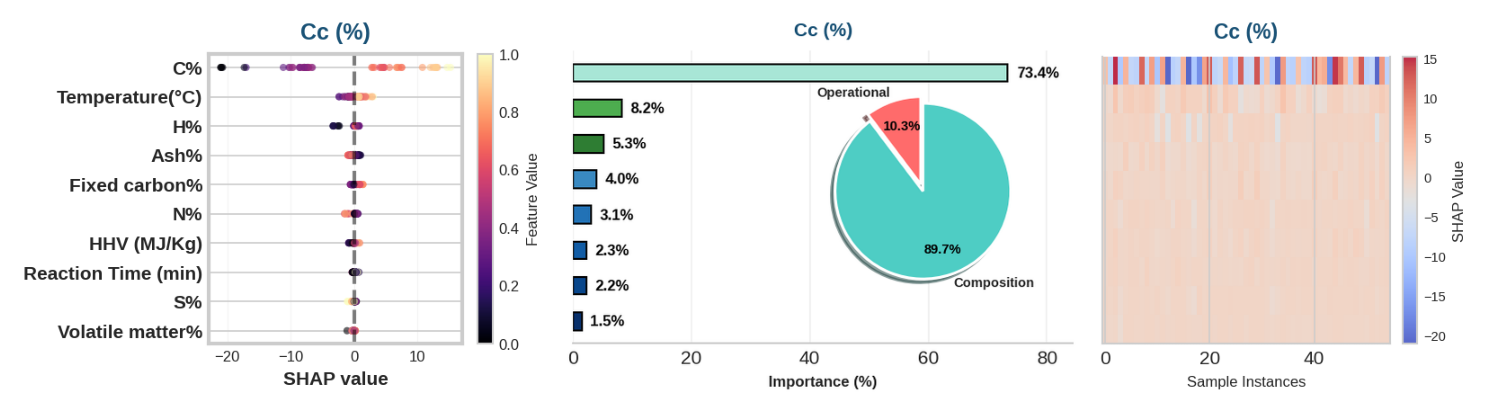

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Cc____.png

📌 Processing 3/13: Hc(%)


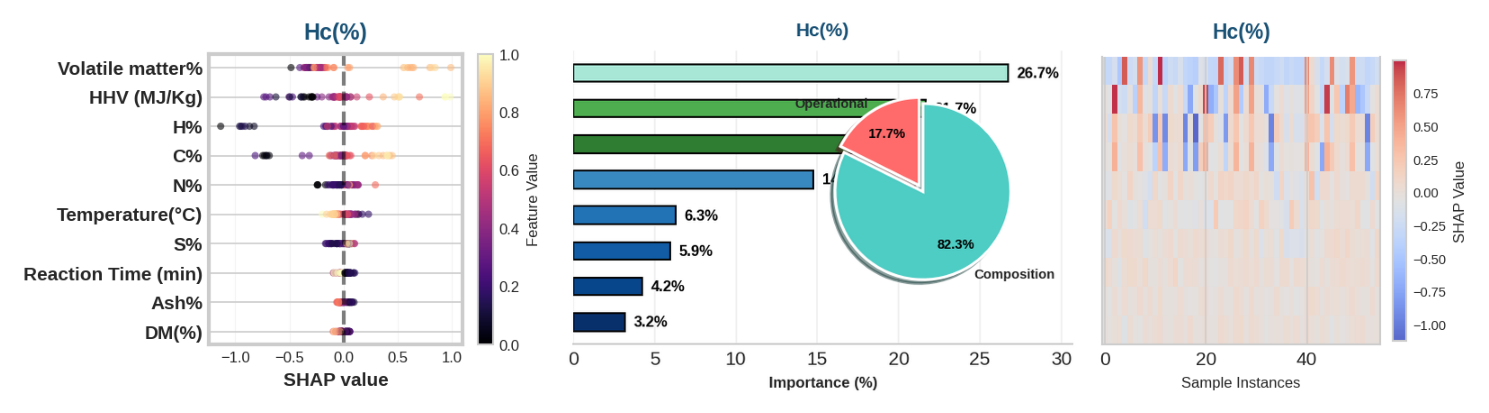

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Hc___.png

📌 Processing 4/13: Nc(%)


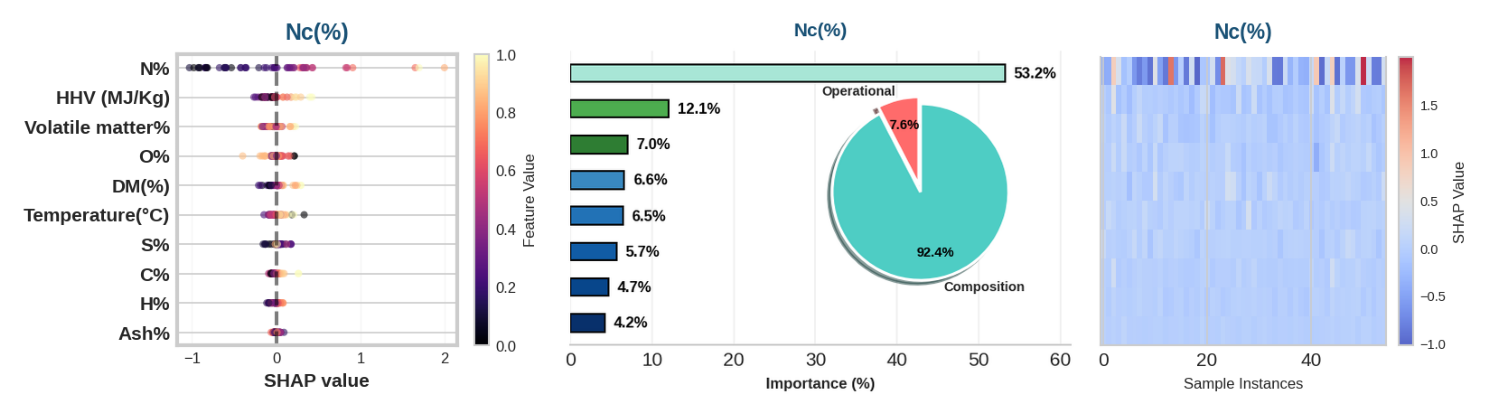

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Nc___.png

📌 Processing 5/13: Sc(%)


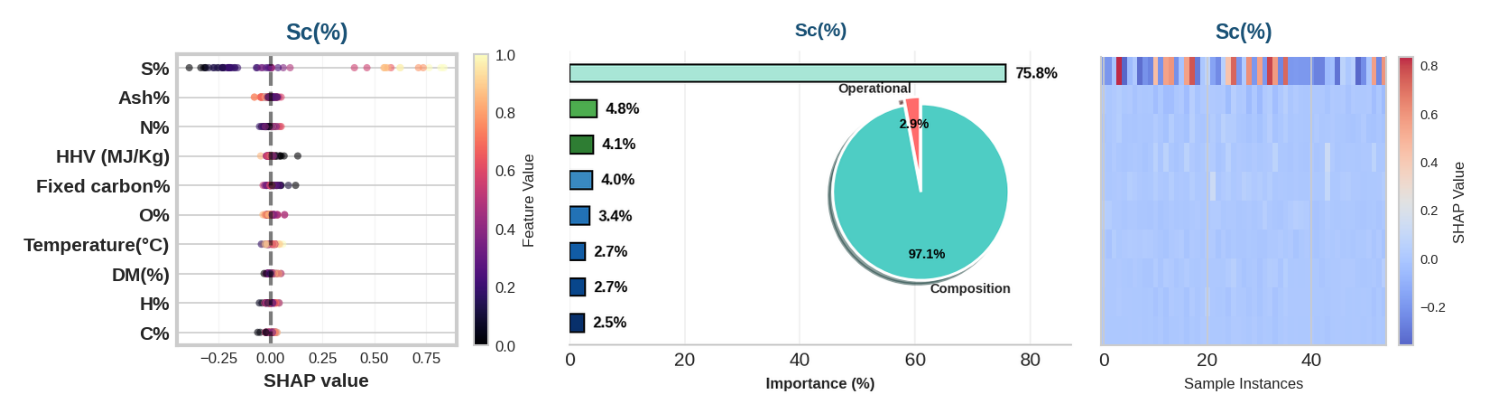

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Sc___.png

📌 Processing 6/13: Oc(%)


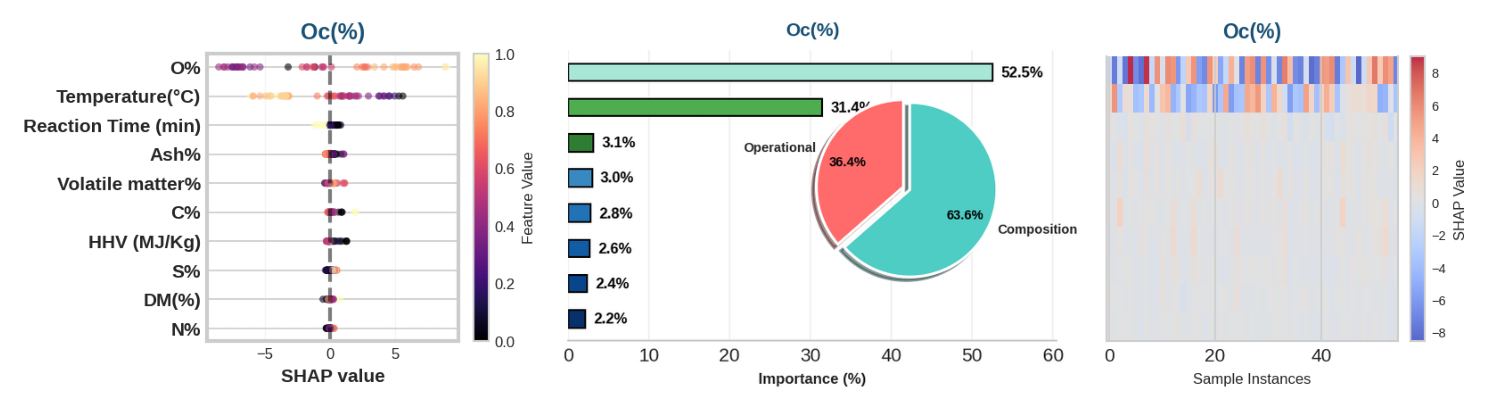

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_Oc___.png

📌 Processing 7/13: HHVc (MJ/Kg)


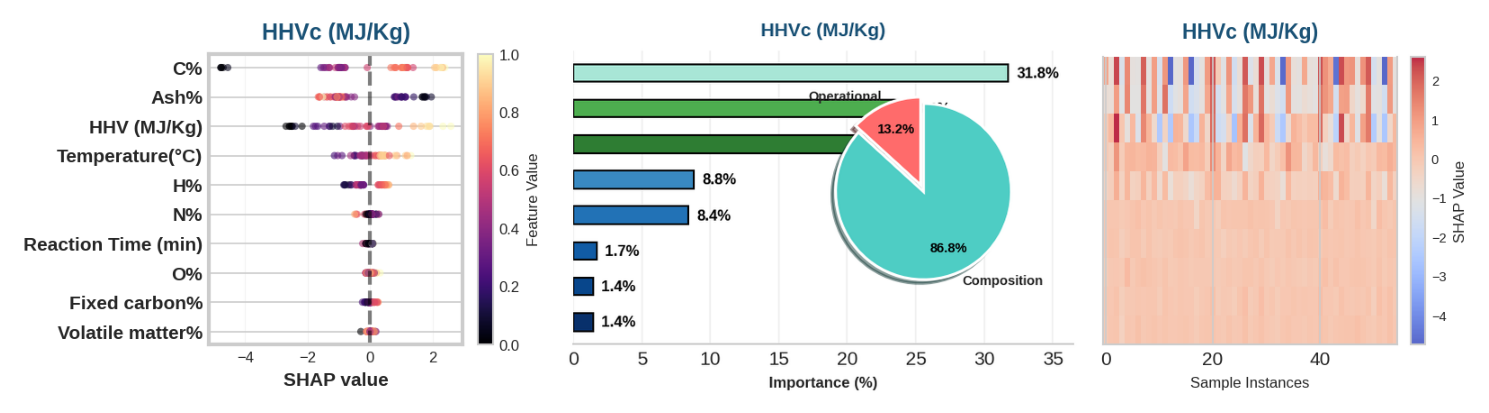

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HHVc__MJ_Kg_.png

📌 Processing 8/13: EY(%)


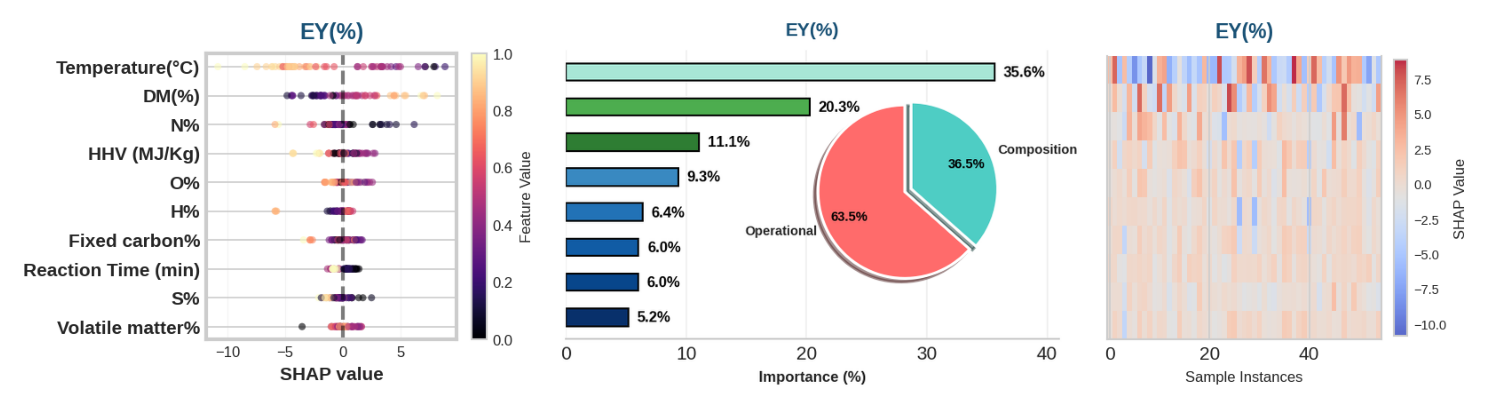

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_EY___.png

📌 Processing 9/13: ED(%)


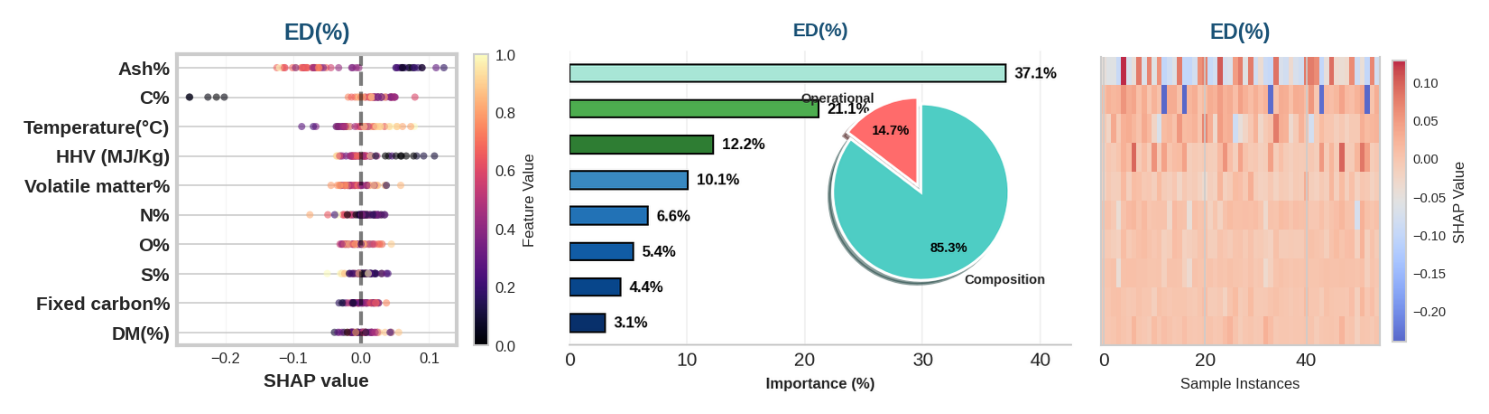

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_ED___.png

📌 Processing 10/13: CR(%)


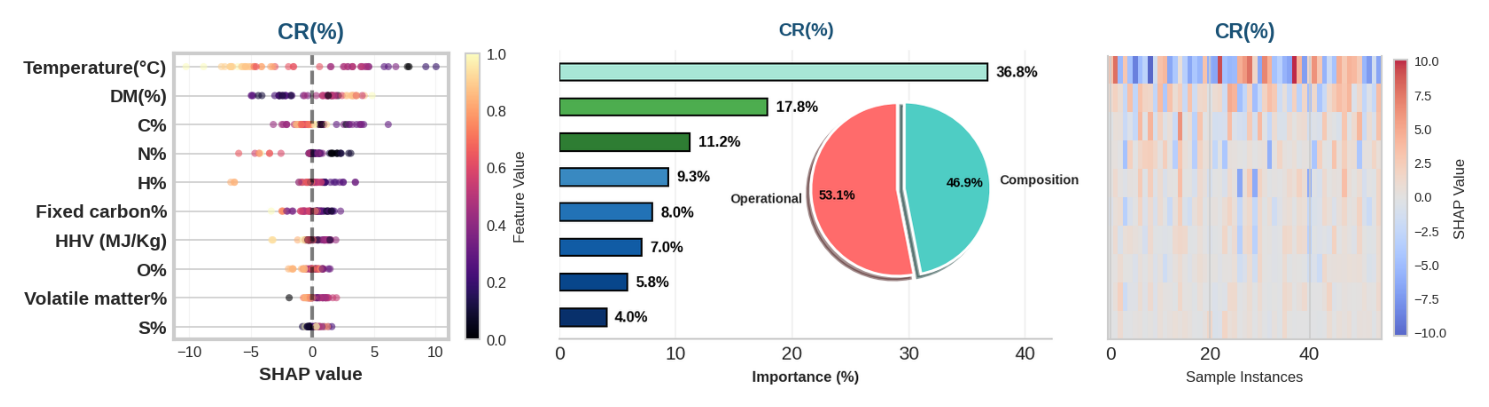

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_CR___.png

📌 Processing 11/13: HC- Volatile matter%


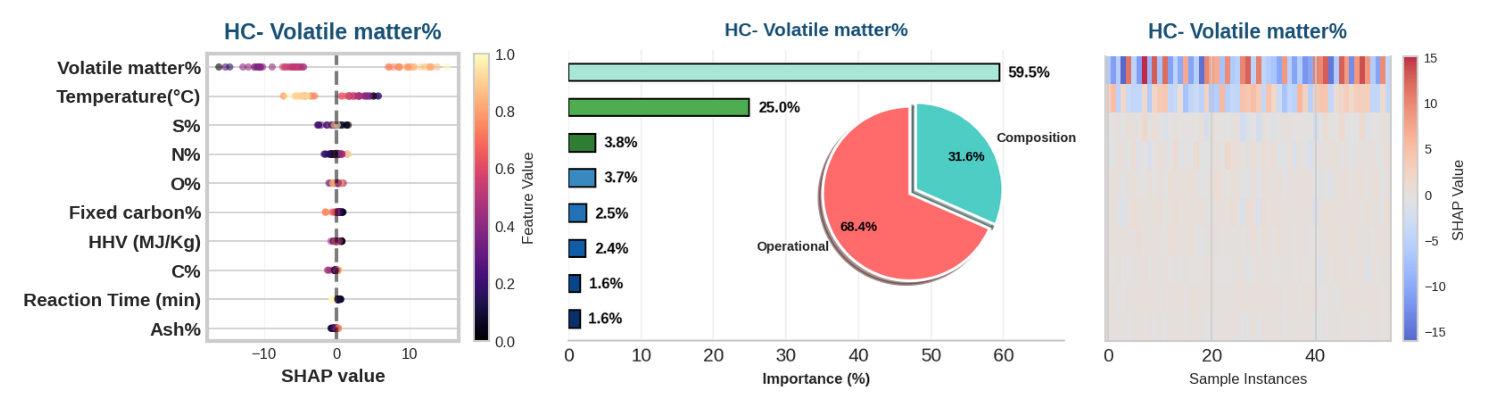

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Volatile_matter_.png

📌 Processing 12/13: HC- Fixed carbon%


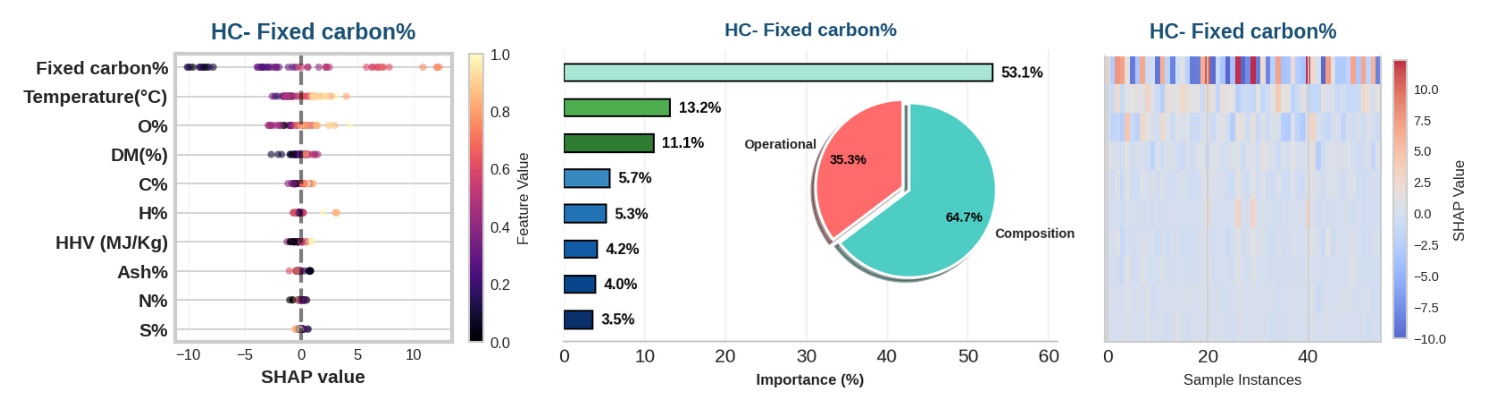

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png

📌 Processing 13/13: HC- Ash(%)


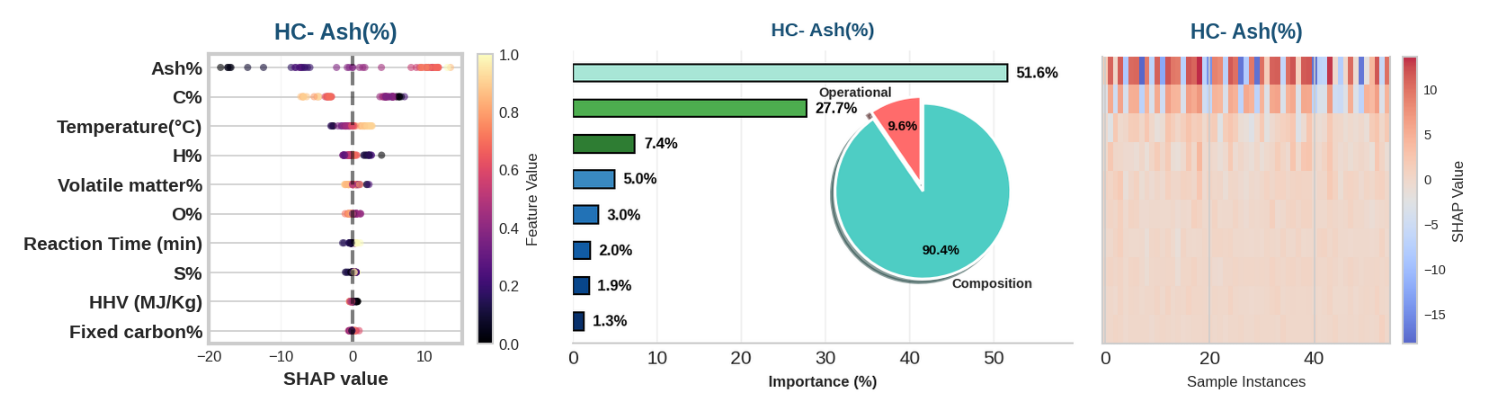

   ✅ Saved: /kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png

✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!

📥 Download the combined plots:

📄 yield(%):


/kaggle/working/shap_combined_three/shap_combined_yield___.png


📄 Cc (%):


/kaggle/working/shap_combined_three/shap_combined_Cc____.png


📄 Hc(%):


/kaggle/working/shap_combined_three/shap_combined_Hc___.png

... (17 outputs left out)

/kaggle/working/shap_combined_three/shap_combined_HC-_Fixed_carbon_.png


📄 HC- Ash(%):


/kaggle/working/shap_combined_three/shap_combined_HC-_Ash___.png


📂 All files are stored in: /kaggle/working/shap_combined_three/


In [16]:
# ============================================
# COMBINE THREE PLOTS SIDE BY SIDE (NO CHANGES)
# ============================================

print("\n" + "="*80)
print("🎨 COMBINING THREE PLOTS SIDE BY SIDE FOR EACH OUTPUT")
print("="*80)

import numpy as np
import matplotlib.pyplot as plt
import os
import re
from PIL import Image
import io
import warnings
warnings.filterwarnings('ignore')

# ============================================
# IMPORT THE THREE CODES EXACTLY AS THEY ARE
# ============================================

# First, let's save the three original codes as functions
# but keep them EXACTLY as you provided

import shap
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

# Create output folder
output_dir = '/kaggle/working/shap_combined_three'
os.makedirs(output_dir, exist_ok=True)

# ============================================
# FUNCTION 1: BEESWARM (FROM FIRST CODE - EXACT)
# ============================================
def generate_beeswarm_plot(shap_values, col, idx):
    """Generate beeswarm plot exactly as in first code"""
    magma_cmap = plt.cm.get_cmap('magma')
    
    FIGURE_WIDTH = 4
    FIGURE_HEIGHT = 3
    FONT_SIZE = 10
    LINE_WIDTH = 2
    MAX_DISPLAY = 10
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:MAX_DISPLAY]
    sorted_idx = sorted_idx[::-1]
    
    fig, ax = plt.subplots(figsize=(FIGURE_WIDTH, FIGURE_HEIGHT), dpi=100)
    
    for i, feat_idx in enumerate(sorted_idx):
        shap_vals = shap_values[:, feat_idx]
        jitter = np.random.normal(0, 0.015, len(shap_vals))
        x = shap_vals + jitter
        y = np.ones(len(shap_vals)) * i
        
        feature_vals = X_test_scaled[:, feat_idx]
        norm_vals = (feature_vals - feature_vals.min()) / (feature_vals.max() - feature_vals.min() + 1e-8)
        colors = magma_cmap(norm_vals)
        
        ax.scatter(x, y, c=colors, alpha=0.6, s=15, edgecolors='none')
    
    ax.set_yticks(range(len(sorted_idx)))
    ax.set_yticklabels([input_cols[i] for i in sorted_idx], 
                       fontsize=FONT_SIZE, 
                       fontweight='bold')
    
    ax.spines['left'].set_linewidth(LINE_WIDTH)
    ax.spines['bottom'].set_linewidth(LINE_WIDTH)
    ax.spines['top'].set_linewidth(LINE_WIDTH)
    ax.spines['right'].set_linewidth(LINE_WIDTH)
    
    ax.tick_params(axis='x', labelsize=FONT_SIZE-2, width=LINE_WIDTH)
    ax.tick_params(axis='y', width=LINE_WIDTH)
    
    ax.axvline(x=0, color='black', linestyle='--', alpha=0.5, linewidth=LINE_WIDTH)
    ax.grid(True, alpha=0.2, axis='x', linestyle='-', linewidth=0.5)
    
    ax.set_xlabel('SHAP value', fontsize=FONT_SIZE, fontweight='bold')
    ax.set_title(f'{col}', fontsize=FONT_SIZE+2, fontweight='bold', color='#1A5276', pad=8)
    
    sm = plt.cm.ScalarMappable(cmap=magma_cmap, 
                               norm=plt.Normalize(vmin=0, vmax=1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=1.0)
    cbar.set_label('Feature Value', fontsize=FONT_SIZE-2)
    cbar.ax.tick_params(labelsize=FONT_SIZE-2)
    
    plt.tight_layout(pad=1.0)
    
    # Save to buffer
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 2: 3D DONUT (FROM SECOND CODE - EXACT)
# ============================================
def generate_donut_plot(shap_values, col, idx):
    """Generate 3D donut plot exactly as in second code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1]
    
    top_k = min(8, len(input_cols))
    top_importance = importance[sorted_idx][:top_k]
    top_names = [input_cols[i] for i in sorted_idx[:top_k]]
    
    total_importance = np.sum(top_importance)
    percentages = (top_importance / total_importance) * 100
    
    top_names = top_names[::-1]
    percentages = percentages[::-1]
    top_importance = top_importance[::-1]
    
    fig, ax = plt.subplots(figsize=(4, 3))
    
    colors = plt.cm.Blues(np.linspace(0.4, 1, len(top_names)))[::-1]
    
    if len(colors) >= 3:
        colors[-3] = (0.18, 0.49, 0.20, 1.0)
    if len(colors) >= 2:
        colors[-2] = (0.30, 0.68, 0.31, 1.0)
    if len(colors) >= 1:
        colors[-1] = (0.66, 0.90, 0.84, 1.0)
    
    y_pos = np.arange(len(top_names))
    bars = ax.barh(y_pos, percentages, color=colors, height=0.5, edgecolor='black')
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    max_width = percentages.max()
    for bar, pct in zip(bars, percentages):
        width = bar.get_width()
        x_pos = width + (max_width * 0.02)
        ax.text(x_pos, bar.get_y() + bar.get_height()/2, 
                f'{pct:.1f}%', 
                ha='left', va='center', fontsize=8, fontweight='bold', color='black')
    
    ax.set_xlim(0, max_width * 1.15)
    ax.set_xlabel('Importance (%)', fontsize=8, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='x')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    
    axins = inset_axes(ax, width="75%", height="75%", 
                       loc='center', 
                       bbox_to_anchor=(0.20, 0.02, 1, 1), 
                       bbox_transform=ax.transAxes)
    
    group1 = ['Temperature(°C)', 'Reaction Time (min)', 'water Content']
    group2 = ['C%', 'H%', 'N%', 'S%', 'O%', 'Ash%']
    
    group1_imp = 0
    group2_imp = 0
    for name, imp in zip(top_names, top_importance):
        if name in group1:
            group1_imp += imp
        elif name in group2:
            group2_imp += imp
    
    if group1_imp + group2_imp == 0:
        pie_data = [35.7, 64.3]
    else:
        total = group1_imp + group2_imp
        pie_data = [group1_imp / total * 100, group2_imp / total * 100]
    
    labels = ['Operational', 'Composition']
    pie_colors = ['#FF6B6B', '#4ECDC4']
    
    wedges, texts, autotexts = axins.pie(
        pie_data, 
        labels=labels, 
        colors=pie_colors, 
        autopct='%1.1f%%', 
        startangle=90,
        pctdistance=0.7,
        explode=(0.08, 0),
        shadow=True,
        textprops={'fontsize': 7, 'fontweight': 'bold'},
        wedgeprops={
            'edgecolor': 'white',
            'linewidth': 1.5
        }
    )
    
    for autotext in autotexts:
        autotext.set_color('black')
        autotext.set_fontsize(7)
    
    axins.set_title('', fontsize=8, fontweight='bold', pad=5)
    ax.set_title(f'{col}', fontsize=10, fontweight='bold', pad=8, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# FUNCTION 3: HEATMAP (FROM THIRD CODE - EXACT)
# ============================================
def generate_heatmap_plot(shap_values, col, idx):
    """Generate heatmap plot exactly as in third code"""
    
    importance = np.abs(shap_values).mean(axis=0)
    sorted_idx = np.argsort(importance)[::-1][:10]
    shap_subset = shap_values[:, sorted_idx]
    
    fig, ax = plt.subplots(figsize=(3, 3))
    
    im = ax.imshow(shap_subset.T, cmap='coolwarm', aspect='auto', alpha=0.85)
    
    ax.set_yticks([])
    ax.set_yticklabels([])
    ax.set_ylabel('')
    
    ax.spines['top'].set_visible(False)
    
    ax.set_xlabel('Sample Instances', fontsize=8)
    
    cbar = plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('SHAP Value', fontsize=8)
    cbar.ax.tick_params(labelsize=7)
    
    plt.title(f'{col}', fontsize=11, fontweight='bold', pad=10, color='#1A5276')
    
    plt.tight_layout(pad=1.0)
    
    buf = io.BytesIO()
    plt.savefig(buf, format='png', dpi=150, bbox_inches='tight', facecolor='white')
    buf.seek(0)
    img = Image.open(buf)
    plt.close()
    
    return img

# ============================================
# COMBINE ALL THREE PLOTS FOR EACH OUTPUT
# ============================================
print("\n📊 Combining plots for each output...")

for idx, col in enumerate(output_cols):
    print(f"\n📌 Processing {idx+1}/{len(output_cols)}: {col}")
    
    try:
        shap_values = shap_values_dict[col]
        
        # Generate all three plots
        img1 = generate_beeswarm_plot(shap_values, col, idx)
        img2 = generate_donut_plot(shap_values, col, idx)
        img3 = generate_heatmap_plot(shap_values, col, idx)
        
        # Get dimensions
        w1, h1 = img1.size
        w2, h2 = img2.size
        w3, h3 = img3.size
        
        # Use the maximum height
        target_height = max(h1, h2, h3)
        
        # Resize images to same height (maintain aspect ratio)
        img1_resized = img1.resize((int(w1 * target_height / h1), target_height), Image.Resampling.LANCZOS)
        img2_resized = img2.resize((int(w2 * target_height / h2), target_height), Image.Resampling.LANCZOS)
        img3_resized = img3.resize((int(w3 * target_height / h3), target_height), Image.Resampling.LANCZOS)
        
        # Create combined image
        total_width = img1_resized.width + img2_resized.width + img3_resized.width
        combined = Image.new('RGB', (total_width, target_height), 'white')
        
        # Paste images side by side
        x_offset = 0
        combined.paste(img1_resized, (x_offset, 0))
        x_offset += img1_resized.width
        combined.paste(img2_resized, (x_offset, 0))
        x_offset += img2_resized.width
        combined.paste(img3_resized, (x_offset, 0))
        
        # Save
        safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
        save_path = f'{output_dir}/shap_combined_{safe_filename}.png'
        combined.save(save_path, dpi=(600, 600))
        
        # Display
        plt.figure(figsize=(15, 5))
        plt.imshow(combined)
        plt.axis('off')
        plt.tight_layout()
        plt.show()
        
        print(f"   ✅ Saved: {save_path}")
        
    except Exception as e:
        print(f"   ⚠️ Error in {col}: {e}")
        import traceback
        traceback.print_exc()

print("\n" + "="*80)
print("✅ ALL COMBINED PLOTS GENERATED SUCCESSFULLY!")
print("="*80)

# Display download links
from IPython.display import FileLink, display
print("\n📥 Download the combined plots:")
for col in output_cols:
    safe_filename = re.sub(r'[\\/*?:"<>|\s()%]', '_', col)
    file_name = f'shap_combined_{safe_filename}.png'
    file_path = f'{output_dir}/{file_name}'
    if os.path.exists(file_path):
        print(f"\n📄 {col}:")
        display(FileLink(file_path))

print(f"\n📂 All files are stored in: {output_dir}/")